In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [20]:
# Path to the customer churn dataset.
csv_path = r"C:\Users\DELL\Documents\EDA\IT_customer_churn.csv"

# Load the CSV into a pandas DataFrame for analysis.
raw_df = pd.read_csv(csv_path)

# Report the dataset dimensions and preview the first five records.
print(raw_df.shape)
raw_df.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# Load and Inspect the Customer Churn Data

This section imports the dataset from the specified CSV path using pandas. The resulting `df` DataFrame is used for subsequent exploratory data analysis. `df.shape` reports the number of rows and columns, while `df.head()` displays the first five records.

In [21]:
list(raw_df.columns) #display the column names of the dataset

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

In [22]:
print("="*50)
print("Dataset Information:")
print("="*50)
print(raw_df.info()) #check the data types of each column and the number of non-null values
print("="*50)
print('Distinct data types:')
print(raw_df.dtypes.unique()) #check the distinct data types of the dataset
print("="*50)
numeric_columns = raw_df.select_dtypes(include=['number']).columns.tolist() #get the list of numeric columns
string_columns = raw_df.select_dtypes(include=['object']).columns.tolist() #get the list of string columns

print("Numeric and String Columns:")

print(f"{len(numeric_columns)} numeric columns: {numeric_columns}")
print(f"{len(string_columns)} string columns: {string_columns}")

print("="*50)


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null 

C:\Users\DELL\AppData\Local\Temp\ipykernel_15112\204023332.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  string_columns = raw_df.select_dtypes(include=['object']).columns.tolist() #get the list of string columns


In [23]:
# Check how many unique values there are in each column.
print("Unique Values in Each Column:")
for col in raw_df.columns:
    series = raw_df[col]
    total_count = series.count()
    unique_count = series.nunique()
    unique_percentage = unique_count / len(raw_df) * 100

    print(
        f"{col}: {series.dtype} - there are {total_count} total values and "
        f"{unique_count} unique values; {unique_percentage:.2f}% of non-null values are unique."
    )

Unique Values in Each Column:
gender: str - there are 7043 total values and 2 unique values; 0.03% of non-null values are unique.
SeniorCitizen: int64 - there are 7043 total values and 2 unique values; 0.03% of non-null values are unique.
Partner: str - there are 7043 total values and 2 unique values; 0.03% of non-null values are unique.
Dependents: str - there are 7043 total values and 2 unique values; 0.03% of non-null values are unique.
tenure: int64 - there are 7043 total values and 73 unique values; 1.04% of non-null values are unique.
PhoneService: str - there are 7043 total values and 2 unique values; 0.03% of non-null values are unique.
MultipleLines: str - there are 7043 total values and 3 unique values; 0.04% of non-null values are unique.
InternetService: str - there are 7043 total values and 3 unique values; 0.04% of non-null values are unique.
OnlineSecurity: str - there are 7043 total values and 3 unique values; 0.04% of non-null values are unique.
OnlineBackup: str - the

In [25]:
# Count null and whitespace-only values in each column
null_counts = raw_df.isna().sum()
blank_counts = raw_df.apply(
    lambda column: column.astype("string").str.strip().eq("").sum()
)

missing_report = pd.DataFrame({
    "null_values": null_counts,
    "blank_values": blank_counts
})

missing_report = missing_report[
    (missing_report["null_values"] > 0) |
    (missing_report["blank_values"] > 0)
]

print(missing_report)

              null_values  blank_values
TotalCharges            0            11


Total charges has 11 blank values, since it is amount column , minimum is 0. replacing 0 for blank #Here human decide which value to impute

In [26]:
#check blank values in the TotalCharges column and replace them with 0
#copy from raw df to trans_df_1 to avoid modifying the original dataset

blank_mask = raw_df["TotalCharges"].astype("string").str.strip().eq("")
raw_df.loc[blank_mask, "TotalCharges"] = "0"
raw_df["TotalCharges"] = pd.to_numeric(raw_df["TotalCharges"], errors="coerce")
trans_df_1 = raw_df.copy()

print(f"Replaced {blank_mask.sum()} blank values with 0")

Replaced 11 blank values with 0


In [27]:
trans_df_1.duplicated().sum() #check for duplicate records in the dataset

np.int64(22)

#conforming no rows having same values or duplicated

Numeric Univariate Analysis:


,count,mean,std,min,25%,50%,75%,max,missing_values
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00,0
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75,0
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80,0


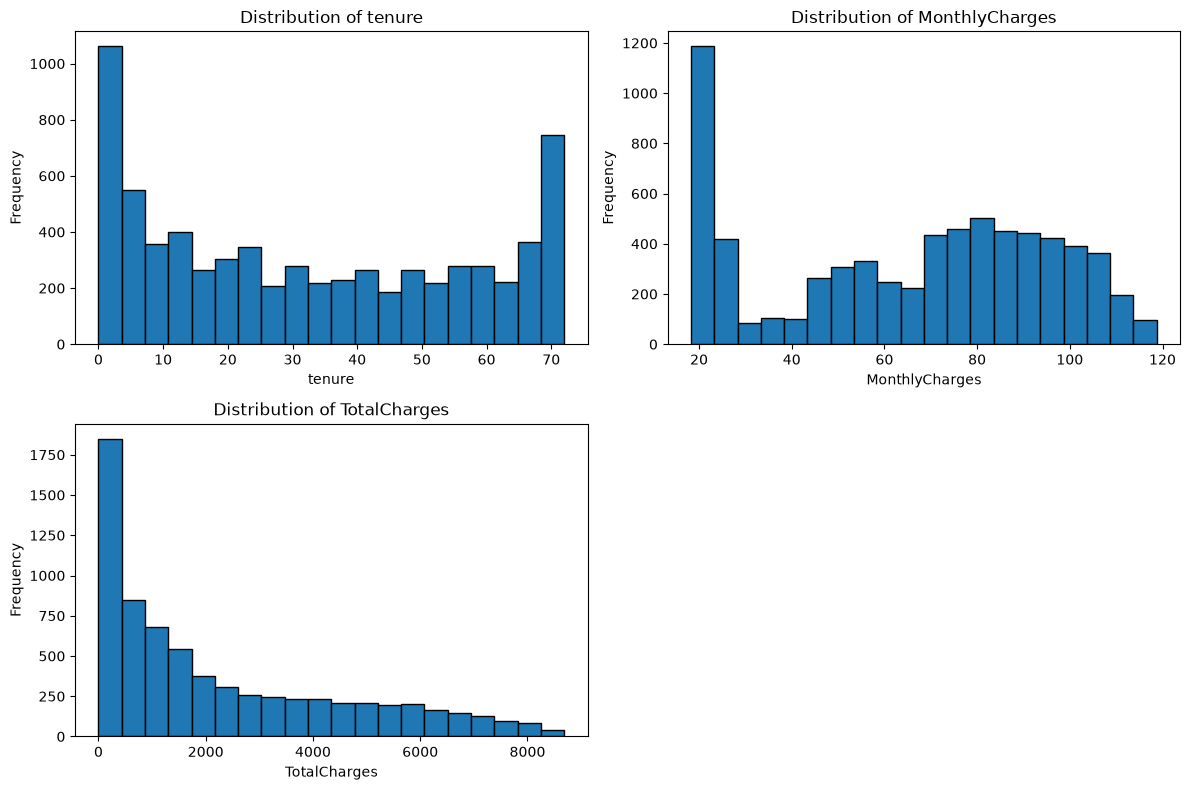

Categorical Univariate Analysis:

gender (2 unique values):


,count,percentage
gender,,
Male,3555,50.48
Female,3488,49.52


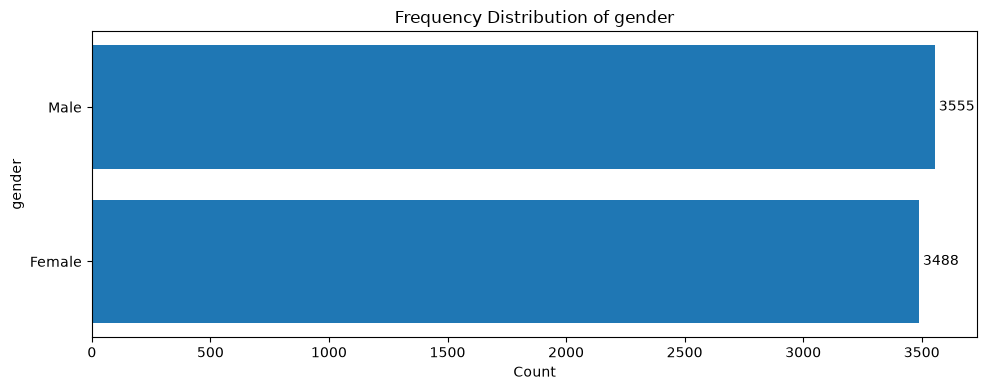


SeniorCitizen (2 unique values):


,count,percentage
SeniorCitizen,,
No,5901,83.79
Yes,1142,16.21


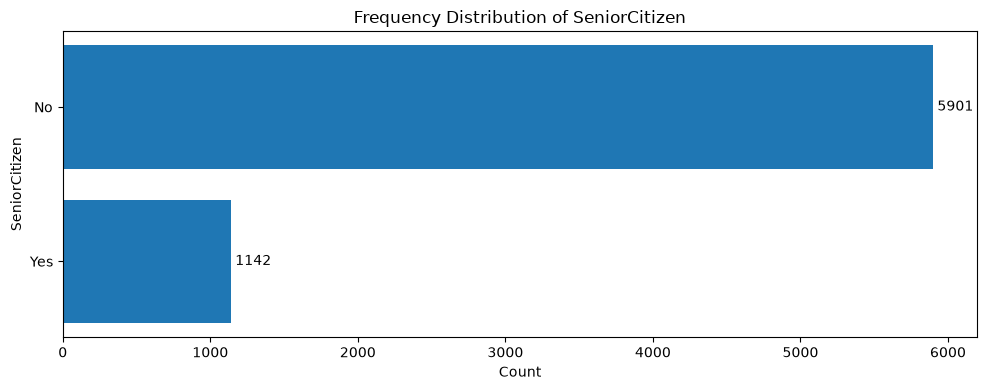


Partner (2 unique values):


,count,percentage
Partner,,
No,3641,51.7
Yes,3402,48.3


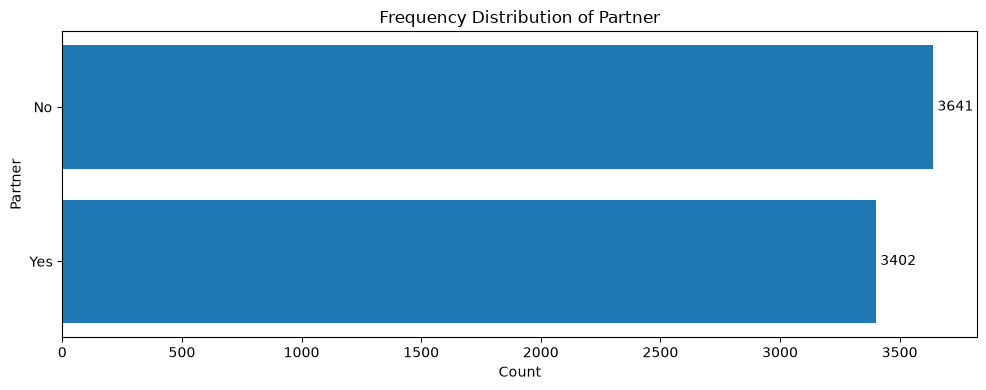


Dependents (2 unique values):


,count,percentage
Dependents,,
No,4933,70.04
Yes,2110,29.96


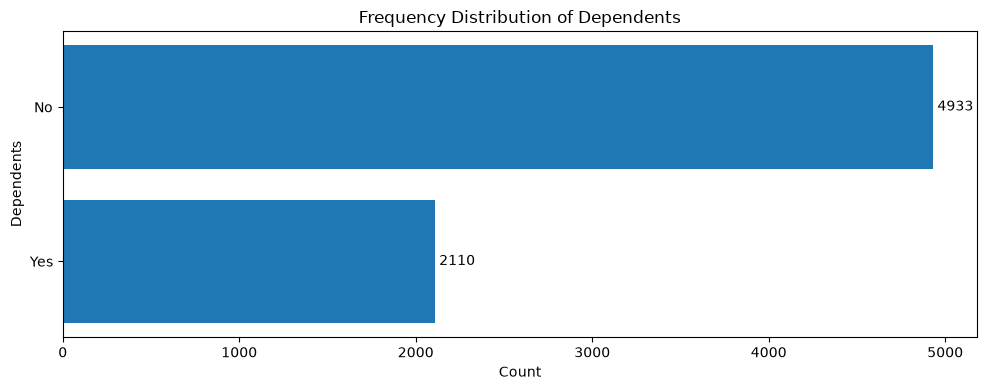


PhoneService (2 unique values):


,count,percentage
PhoneService,,
Yes,6361,90.32
No,682,9.68


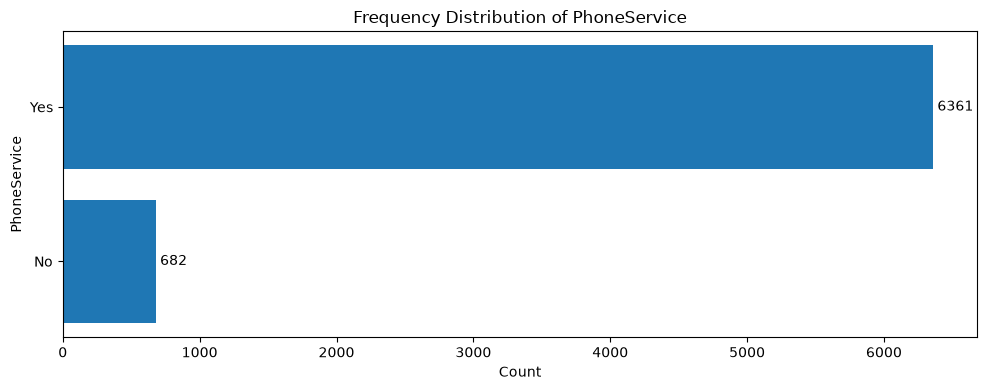


MultipleLines (3 unique values):


,count,percentage
MultipleLines,,
No,3390,48.13
Yes,2971,42.18
No phone service,682,9.68


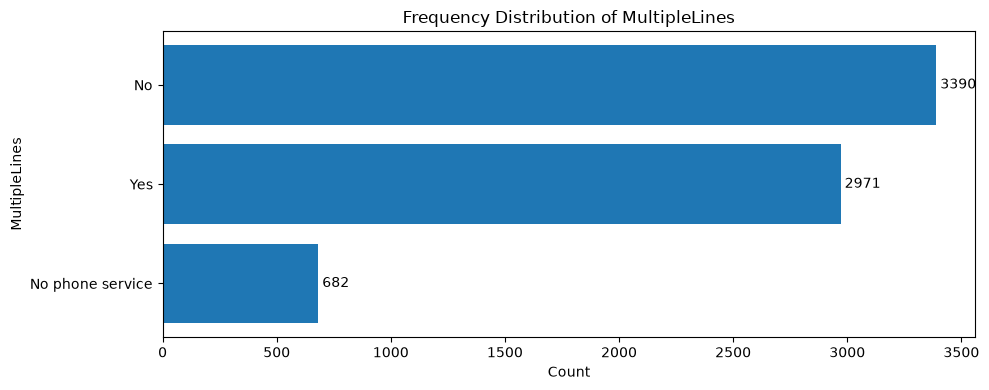


InternetService (3 unique values):


,count,percentage
InternetService,,
Fiber optic,3096,43.96
DSL,2421,34.37
No,1526,21.67


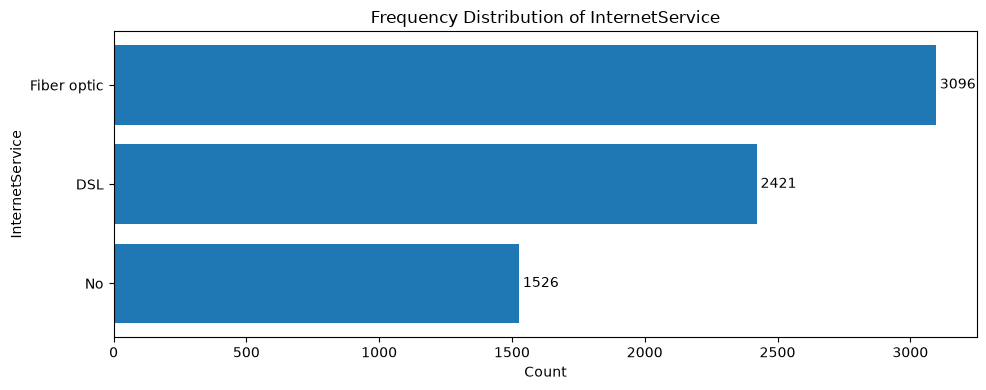


OnlineSecurity (3 unique values):


,count,percentage
OnlineSecurity,,
No,3498,49.67
Yes,2019,28.67
No internet service,1526,21.67


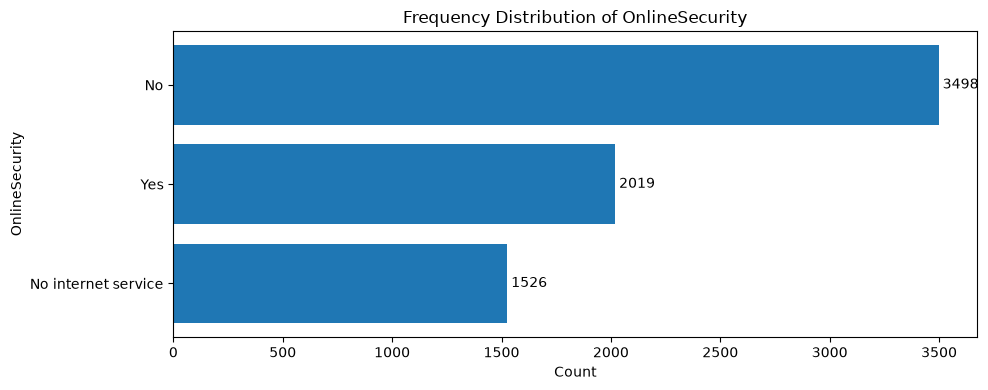


OnlineBackup (3 unique values):


,count,percentage
OnlineBackup,,
No,3088,43.84
Yes,2429,34.49
No internet service,1526,21.67


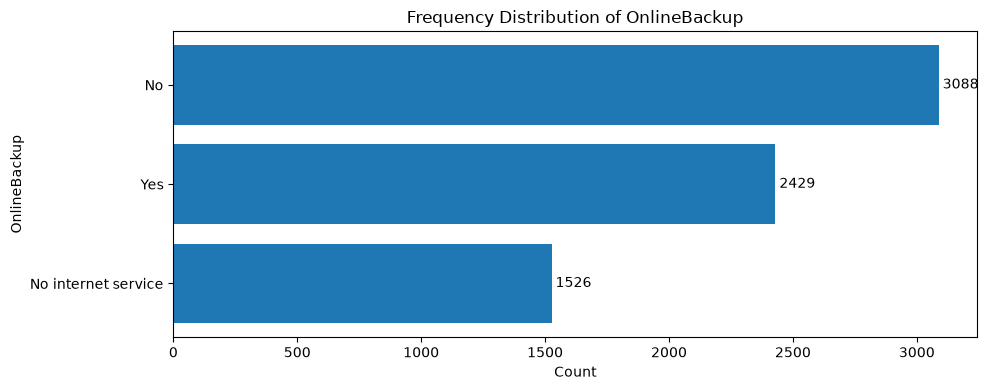


DeviceProtection (3 unique values):


,count,percentage
DeviceProtection,,
No,3095,43.94
Yes,2422,34.39
No internet service,1526,21.67


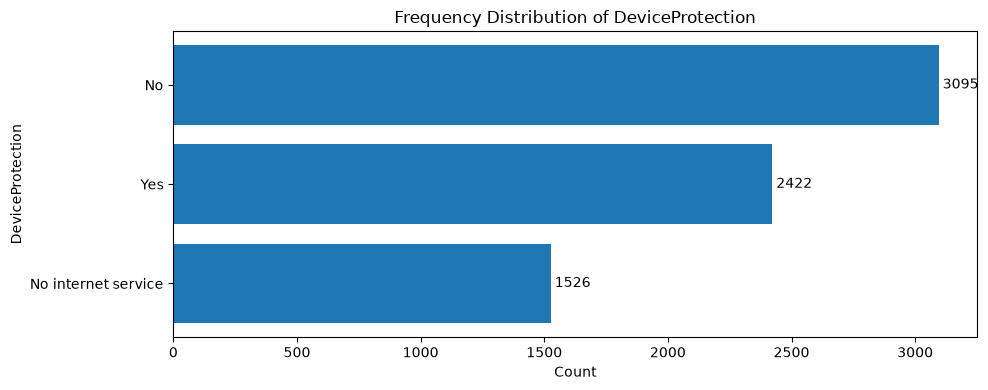


TechSupport (3 unique values):


,count,percentage
TechSupport,,
No,3473,49.31
Yes,2044,29.02
No internet service,1526,21.67


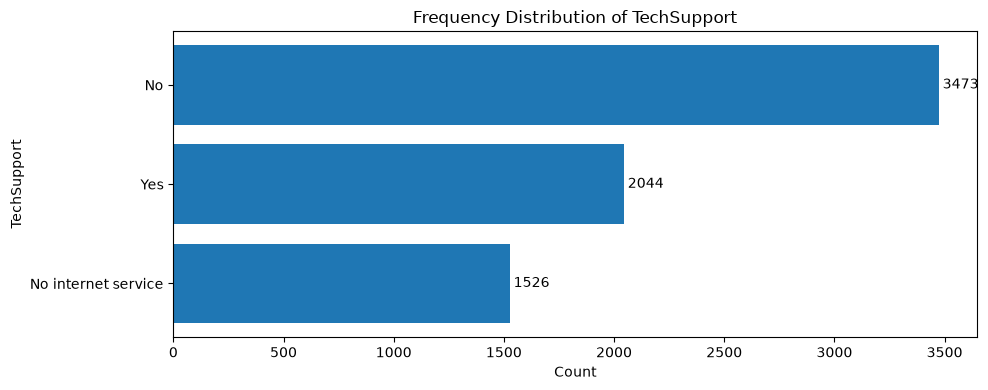


StreamingTV (3 unique values):


,count,percentage
StreamingTV,,
No,2810,39.90
Yes,2707,38.44
No internet service,1526,21.67


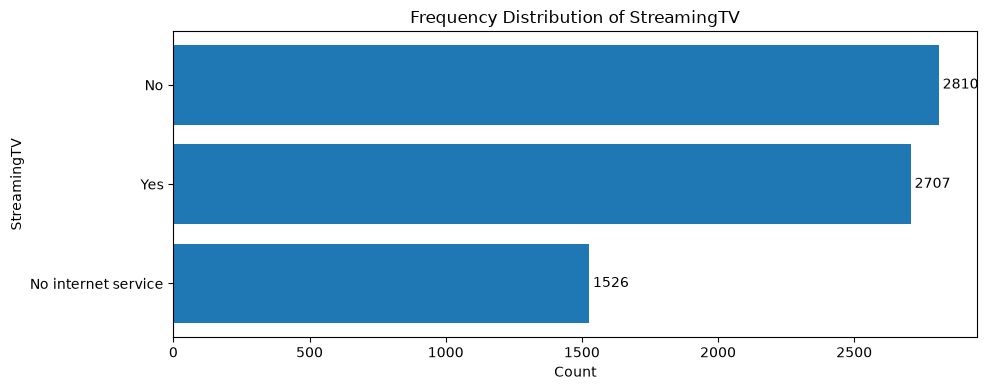


StreamingMovies (3 unique values):


,count,percentage
StreamingMovies,,
No,2785,39.54
Yes,2732,38.79
No internet service,1526,21.67


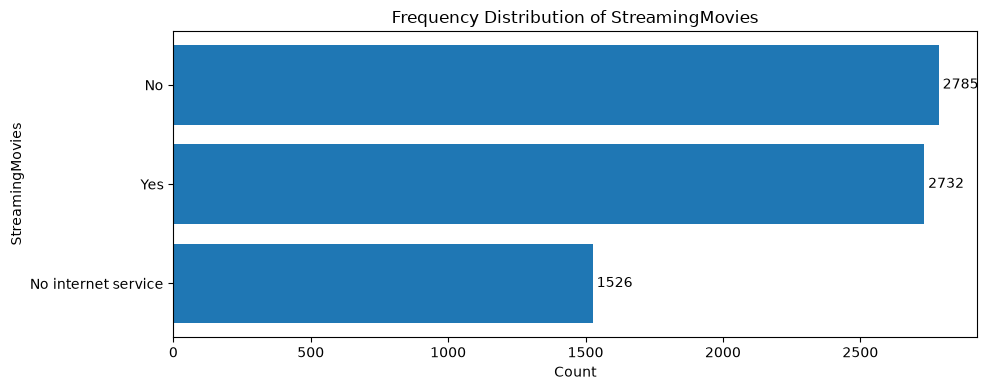


Contract (3 unique values):


,count,percentage
Contract,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91


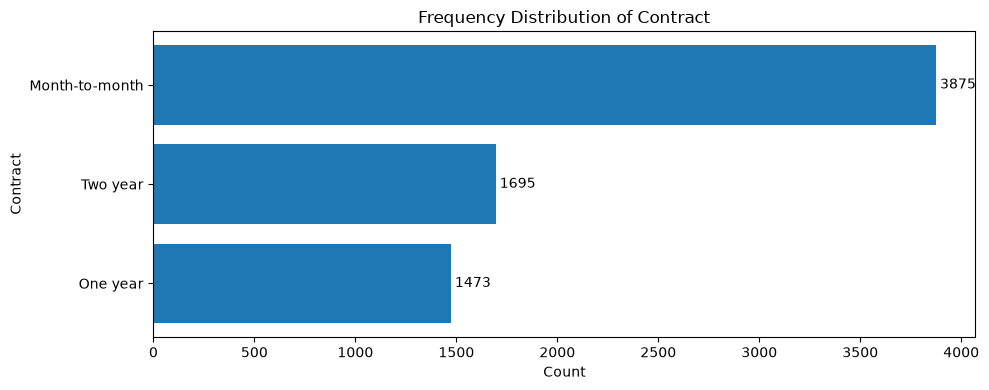


PaperlessBilling (2 unique values):


,count,percentage
PaperlessBilling,,
Yes,4171,59.22
No,2872,40.78


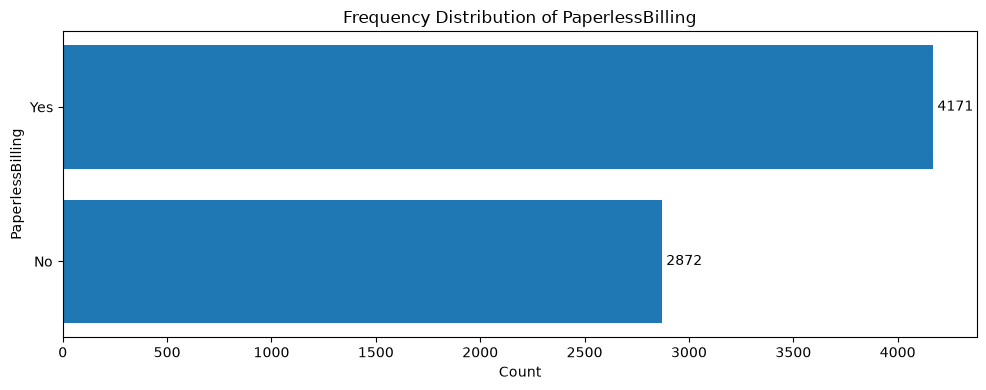


PaymentMethod (4 unique values):


,count,percentage
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61


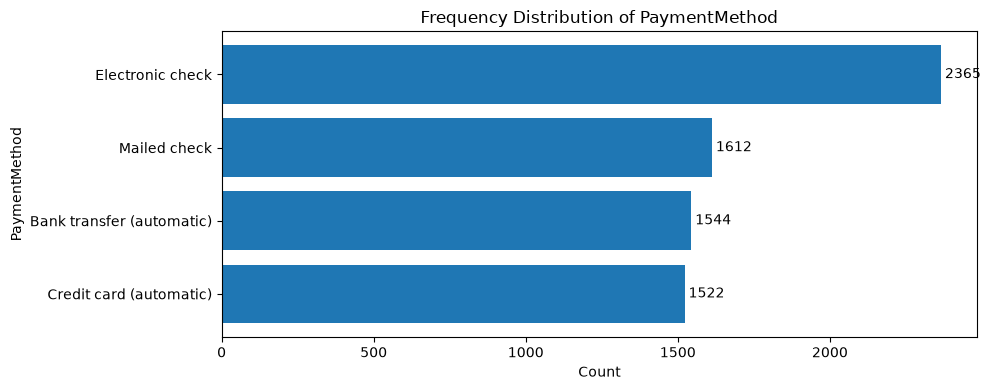


Churn (2 unique values):


,count,percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


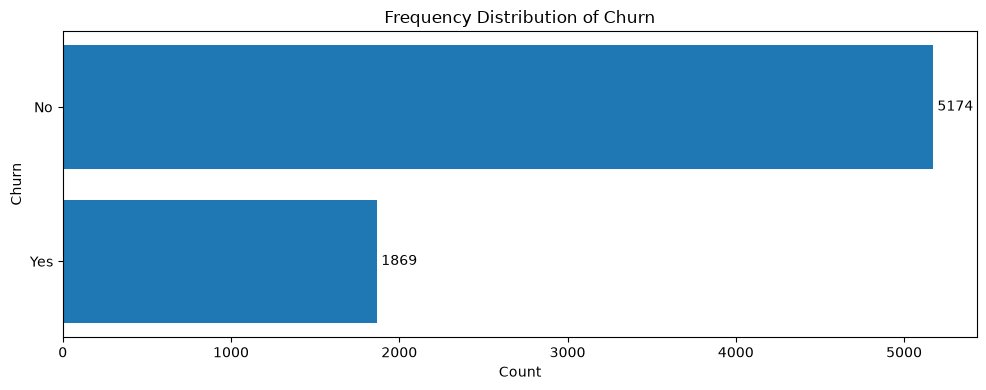

In [28]:
# Frequency distribution of each column in the dataset.
import matplotlib.pyplot as plt

# Treat SeniorCitizen as categorical: 0 means not senior and 1 means senior.
binary_categorical_columns = ["SeniorCitizen"]

analysis_df = trans_df_1.copy()
if "SeniorCitizen" in analysis_df.columns:
    analysis_df["SeniorCitizen"] = analysis_df["SeniorCitizen"].map({
        0: "No",
        1: "Yes"
    })

# Numeric columns: count, mean, standard deviation, quartiles, minimum, and maximum.
numeric_columns = analysis_df.select_dtypes(include="number").columns.tolist()
numeric_columns = [column for column in numeric_columns if column not in binary_categorical_columns]

numeric_summary = analysis_df[numeric_columns].describe().T
numeric_summary["missing_values"] = analysis_df[numeric_columns].isna().sum()
print("Numeric Univariate Analysis:")
display(numeric_summary)

# Plot histograms for numeric columns.
if numeric_columns:
    fig, axes = plt.subplots(
        nrows=(len(numeric_columns) + 1) // 2,
        ncols=2,
        figsize=(12, 4 * ((len(numeric_columns) + 1) // 2))
    )
    axes = axes.flatten() if len(numeric_columns) > 1 else [axes]

    for ax, column in zip(axes, numeric_columns):
        analysis_df[column].plot(kind="hist", bins=20, ax=ax, edgecolor="black")
        ax.set_title(f"Distribution of {column}")
        ax.set_xlabel(column)
        ax.set_ylabel("Frequency")

    for ax in axes[len(numeric_columns):]:
        ax.set_visible(False)

    plt.tight_layout()
    plt.show()

# Categorical/object columns: value counts, percentages, and bar charts.
print("Categorical Univariate Analysis:")
categorical_columns = analysis_df.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()
if binary_categorical_columns[0] in analysis_df.columns and binary_categorical_columns[0] not in categorical_columns:
    categorical_columns.append(binary_categorical_columns[0])

for column in categorical_columns:
    frequencies = analysis_df[column].value_counts(dropna=False)
    percentages = analysis_df[column].value_counts(normalize=True, dropna=False) * 100

    frequency_table = pd.DataFrame({
        "count": frequencies,
        "percentage": percentages.round(2)
    })

    print(f"\n{column} ({analysis_df[column].nunique(dropna=True)} unique values):")
    display(frequency_table)

    chart_data = frequency_table.sort_values("count", ascending=True).tail(15)

    fig, ax = plt.subplots(figsize=(10, max(4, len(chart_data) * 0.35)))
    ax.barh(chart_data.index.astype(str), chart_data["count"])
    ax.set_title(f"Frequency Distribution of {column}")
    ax.set_xlabel("Count")
    ax.set_ylabel(column)

    for index, count in enumerate(chart_data["count"]):
        ax.text(count, index, f" {int(count)}", va="center")

    plt.tight_layout()
    plt.show()

#Univariate analysis provides a fair overview of what the dataset contains.
#It is also important to note that univariate analysis examines each column independently

Senior citizens are a minority, comprising 16.21% of customers, while 83.79% are non-senior citizens.
Gender is evenly distributed: 50.48% male and 49.52% female.
51.70% have partners; 48.30% do not.
70.04% have no dependents.
90.32% use phone service.
Multiple lines: 48.13% no, 42.18% yes, 9.68% no phone service.
Fiber optic is the most common internet service at 43.96%.
49.67% lack online security; 21.67% have no internet service.
43.84% lack online backup; 21.67% have no internet service.
43.94% lack device protection; 21.67% have no internet service.
49.31% lack tech support; 21.67% have no internet service.
Streaming TV and movies usage is nearly balanced.
55.02% use month-to-month contracts.
59.22% use paperless billing.
Electronic check is the leading payment method at 33.58%.
73.46% retained customers versus 26.54% churned customers.


In [29]:
# Merge the phone-service absence category into the No category.
trans_df_1["MultipleLines"] = trans_df_1["MultipleLines"].replace(
    "No phone service", "No"
)
    
print(trans_df_1["MultipleLines"].value_counts(dropna=False))

MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64


In [ ]:
## Bivariate Analysis Against Churn

This section compares each feature with the `Churn` target. Categorical features are summarized using churn percentages within each category, while numeric features are summarized by churn status.


tenure by Churn Status


Churn,No,Yes
count,5174.000000,1869.000000
mean,37.569965,17.979133
std,24.113777,19.531123
min,0.000000,1.000000
25%,15.000000,2.000000
50%,38.000000,10.000000
75%,61.000000,29.000000
max,72.000000,72.000000


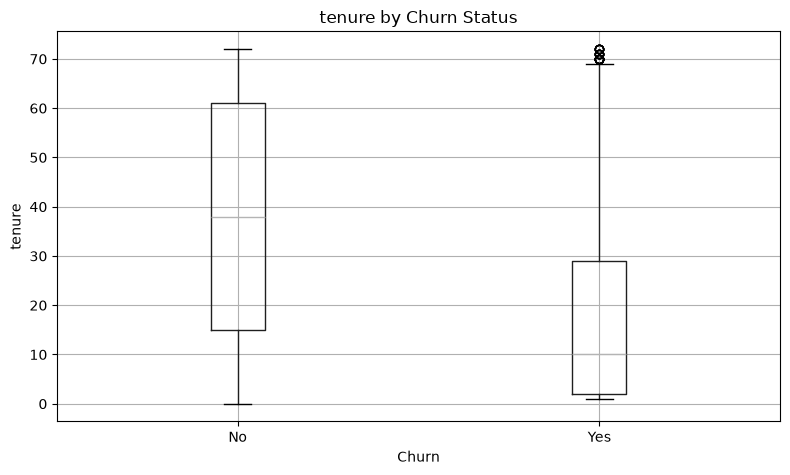


MonthlyCharges by Churn Status


Churn,No,Yes
count,5174.000000,1869.000000
mean,61.265124,74.441332
std,31.092648,24.666053
min,18.250000,18.850000
25%,25.100000,56.150000
50%,64.425000,79.650000
75%,88.400000,94.200000
max,118.750000,118.350000


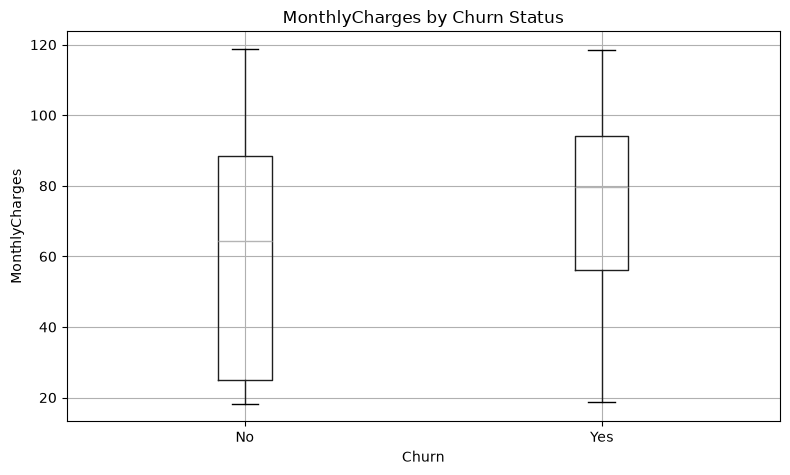


TotalCharges by Churn Status


Churn,No,Yes
count,5174.000000,1869.000000
mean,2549.911442,1531.796094
std,2329.954215,1890.822994
min,0.000000,18.850000
25%,572.900000,134.500000
50%,1679.525000,703.550000
75%,4262.850000,2331.300000
max,8672.450000,8684.800000


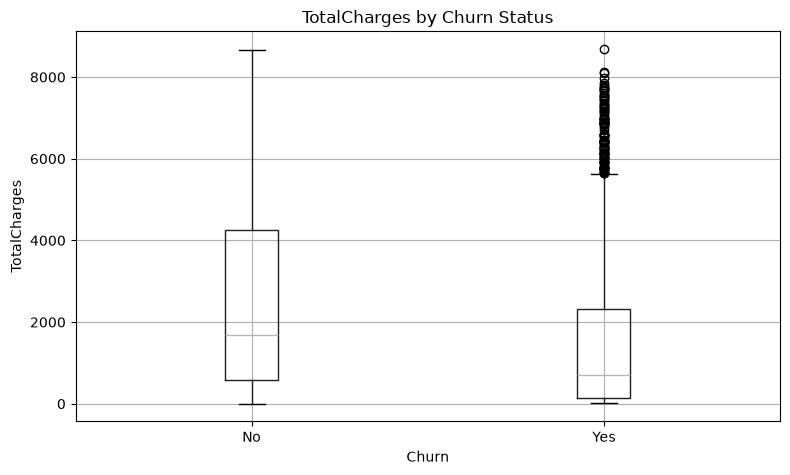

Numeric columns are summarized by both churn categories and shown with box plots.


In [30]:
# Numeric features vs. Churn.
numeric_columns = analysis_df.select_dtypes(include="number").columns.tolist()
numeric_columns = [column for column in numeric_columns if column not in binary_categorical_columns and column != "Churn"]

for column in numeric_columns:
    print(f"\n{column} by Churn Status")
    display(analysis_df.groupby("Churn")[column].describe(  ).T)

    fig, ax = plt.subplots(figsize=(8, 5))
    analysis_df.boxplot(column=column, by="Churn", ax=ax)
    ax.set_title(f"{column} by Churn Status")
    ax.set_xlabel("Churn")
    ax.set_ylabel(column)
    fig.suptitle("")
    plt.tight_layout()
    plt.show()

if numeric_columns:
    print("Numeric columns are summarized by both churn categories and shown with box plots.")


gender vs. Churn
Raw counts:


Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930


Percentage within each category:


Churn,No,Yes
gender,,
Female,73.08,26.92
Male,73.84,26.16


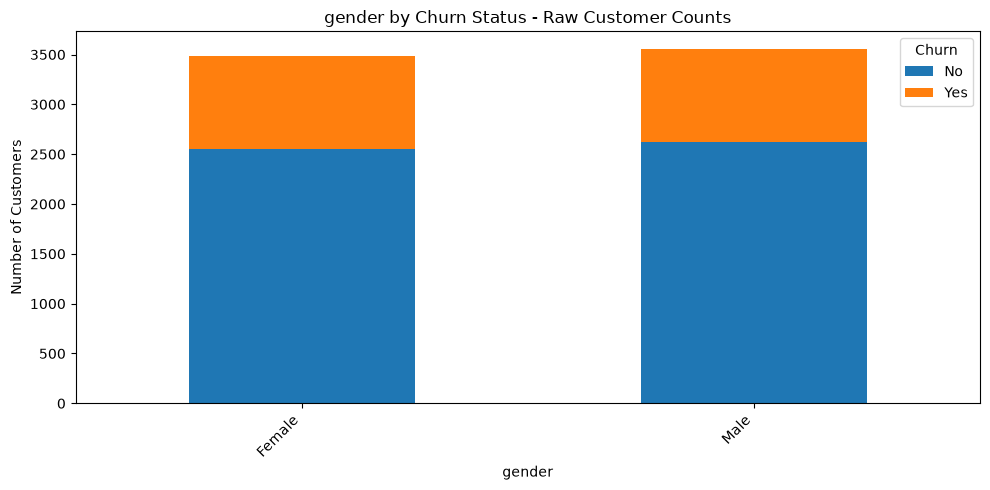

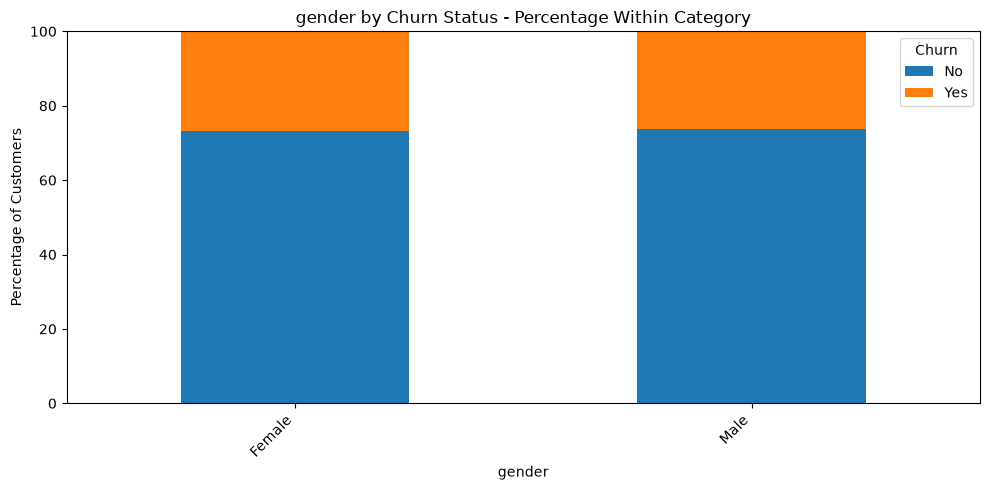


SeniorCitizen vs. Churn
Raw counts:


Churn,No,Yes
SeniorCitizen,,
No,4508,1393
Yes,666,476


Percentage within each category:


Churn,No,Yes
SeniorCitizen,,
No,76.39,23.61
Yes,58.32,41.68


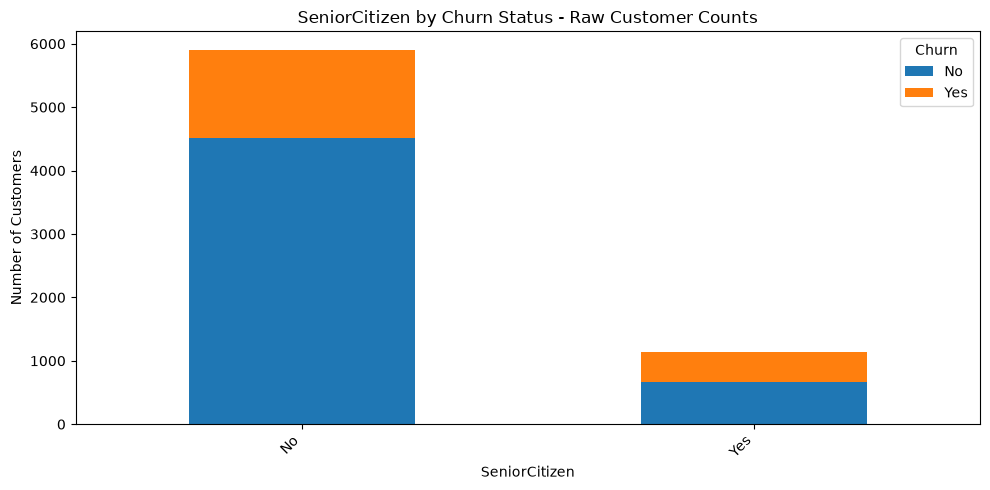

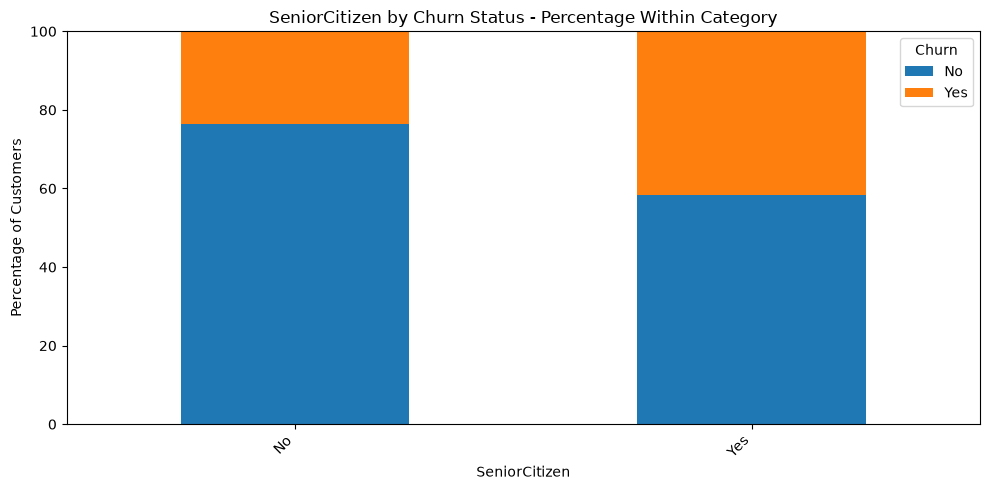


Partner vs. Churn
Raw counts:


Churn,No,Yes
Partner,,
No,2441,1200
Yes,2733,669


Percentage within each category:


Churn,No,Yes
Partner,,
No,67.04,32.96
Yes,80.34,19.66


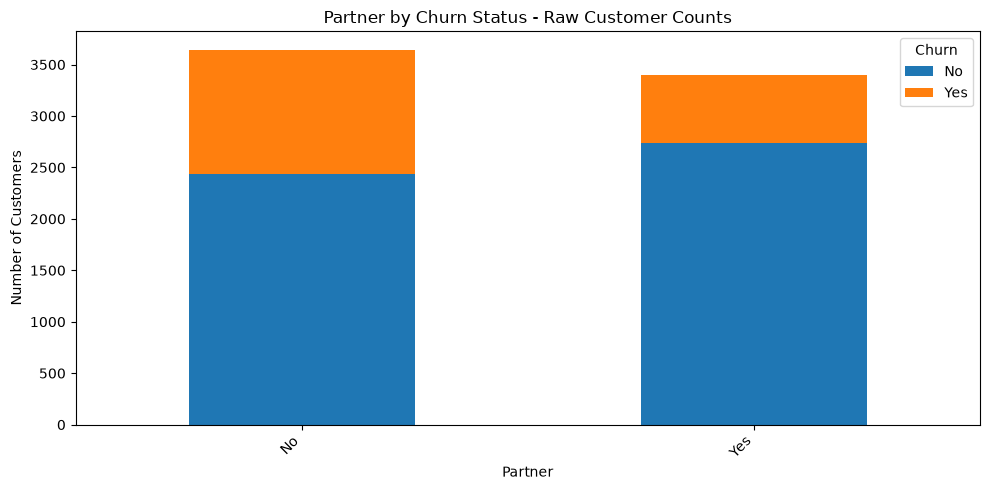

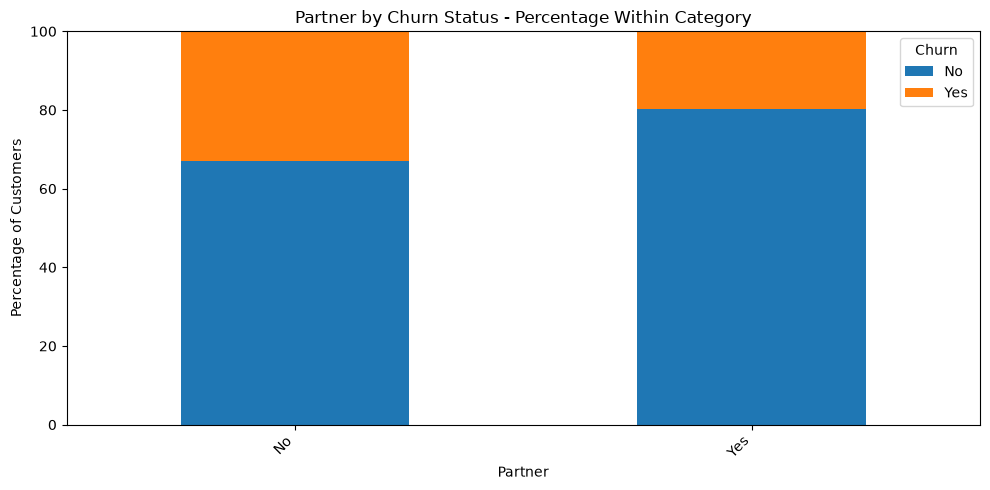


Dependents vs. Churn
Raw counts:


Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326


Percentage within each category:


Churn,No,Yes
Dependents,,
No,68.72,31.28
Yes,84.55,15.45


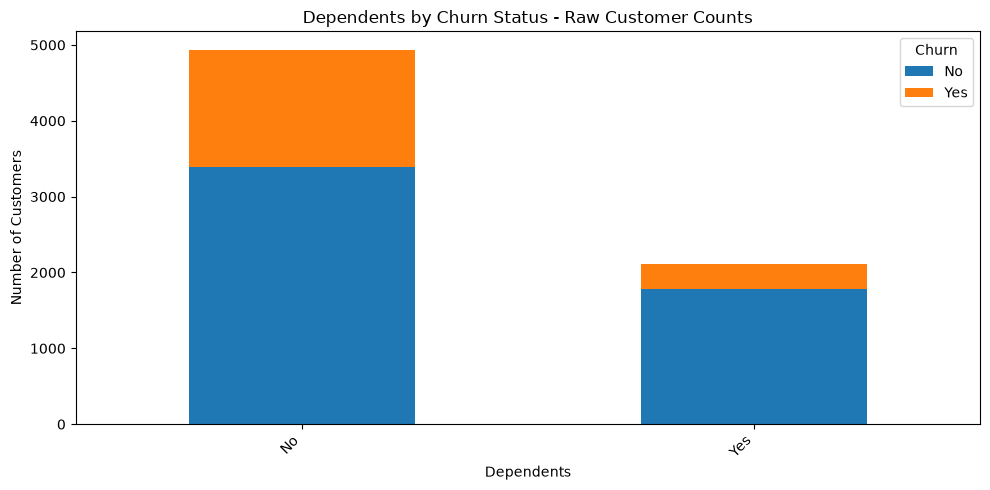

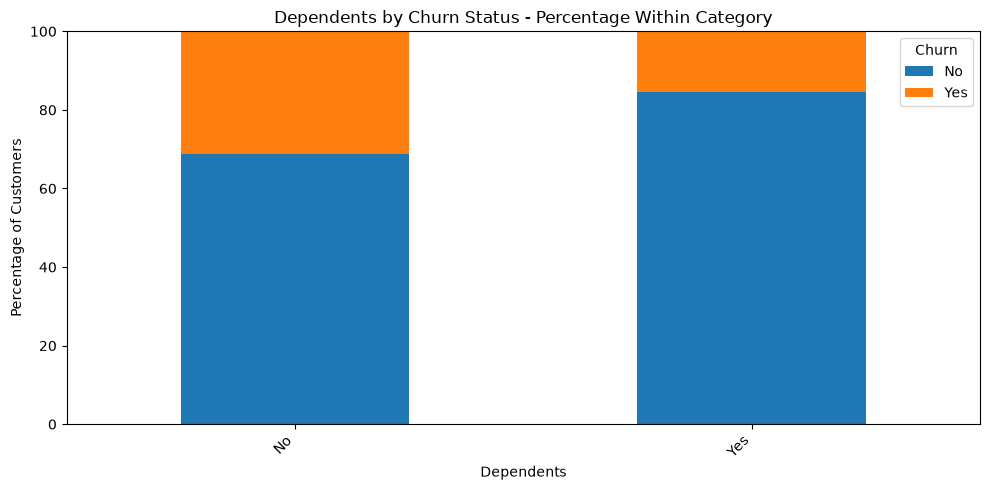


PhoneService vs. Churn
Raw counts:


Churn,No,Yes
PhoneService,,
No,512,170
Yes,4662,1699


Percentage within each category:


Churn,No,Yes
PhoneService,,
No,75.07,24.93
Yes,73.29,26.71


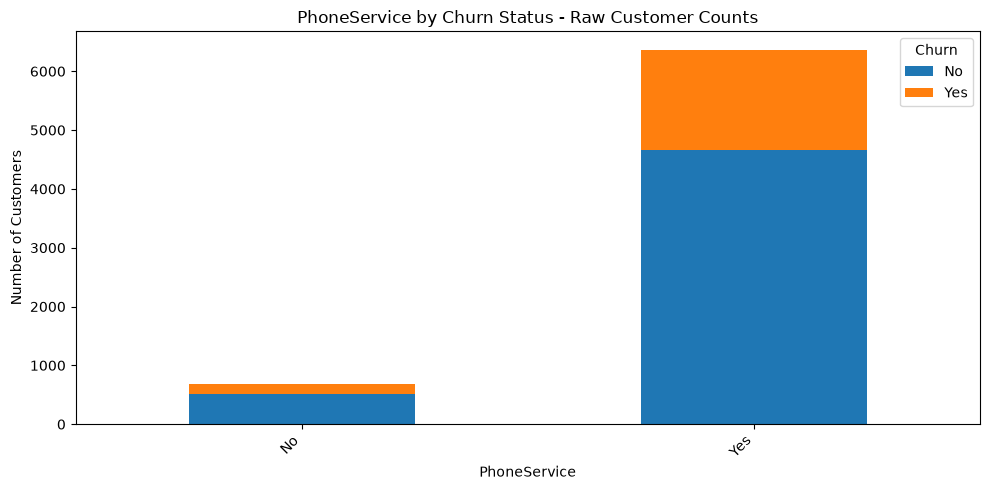

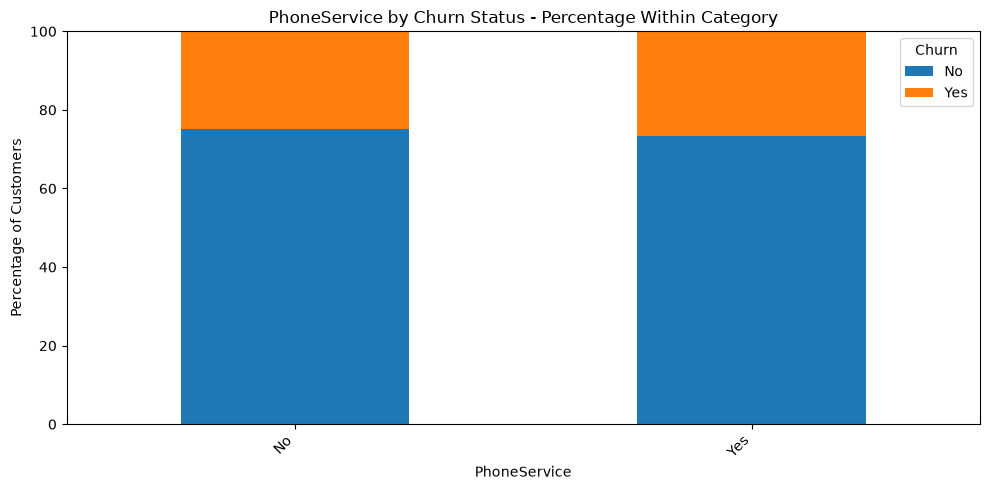


MultipleLines vs. Churn
Raw counts:


Churn,No,Yes
MultipleLines,,
No,3053,1019
Yes,2121,850


Percentage within each category:


Churn,No,Yes
MultipleLines,,
No,74.98,25.02
Yes,71.39,28.61


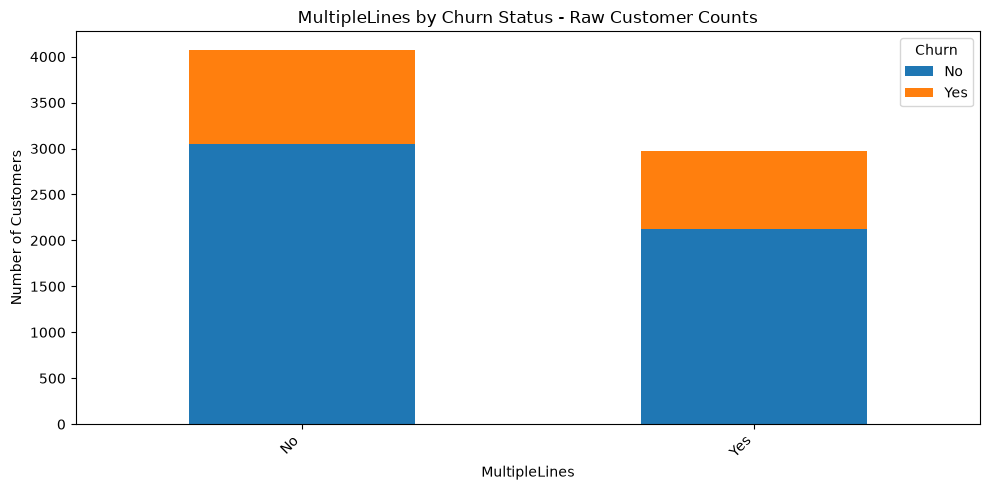

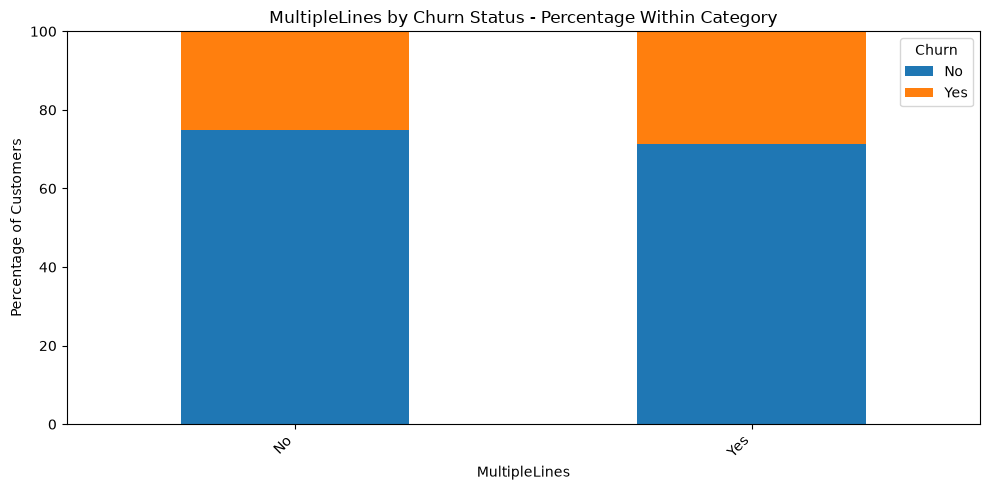


InternetService vs. Churn
Raw counts:


Churn,No,Yes
InternetService,,
DSL,1962,459
Fiber optic,1799,1297
No,1413,113


Percentage within each category:


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


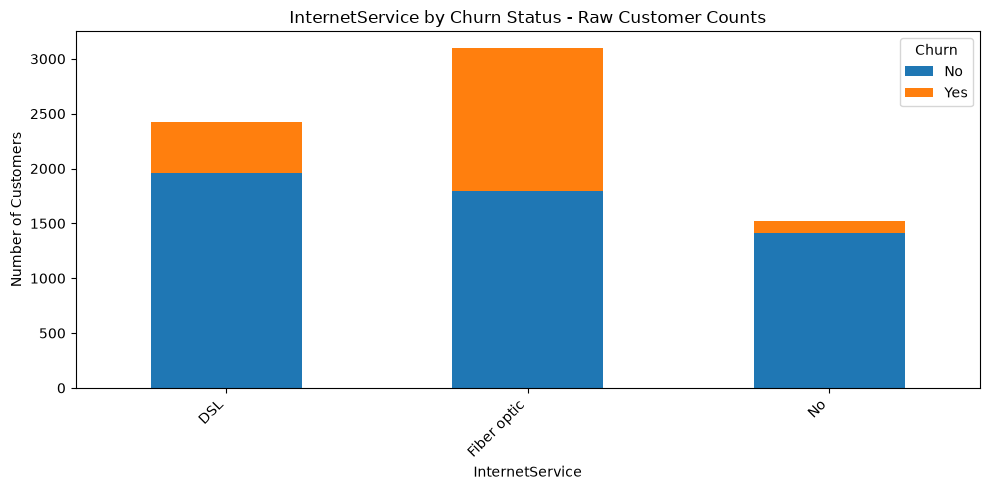

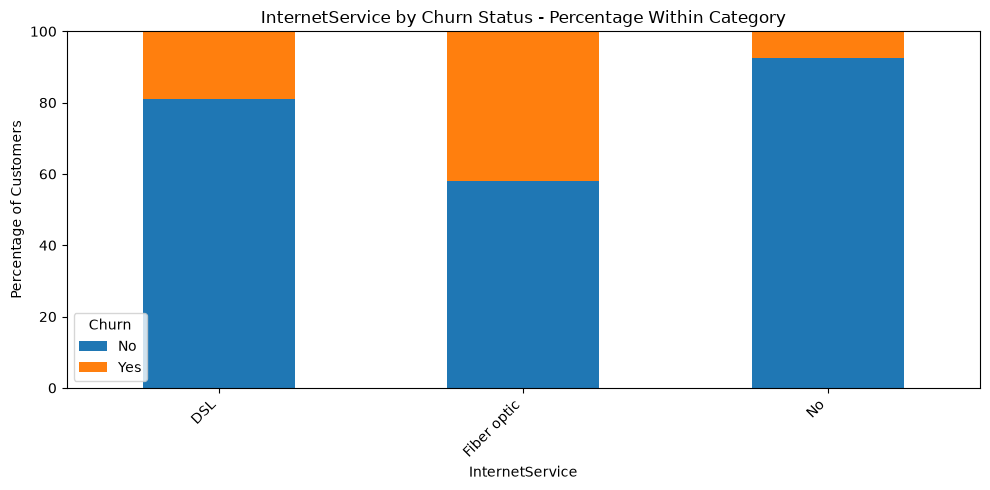


OnlineSecurity vs. Churn
Raw counts:


Churn,No,Yes
OnlineSecurity,,
No,2037,1461
No internet service,1413,113
Yes,1724,295


Percentage within each category:


Churn,No,Yes
OnlineSecurity,,
No,58.23,41.77
No internet service,92.60,7.40
Yes,85.39,14.61


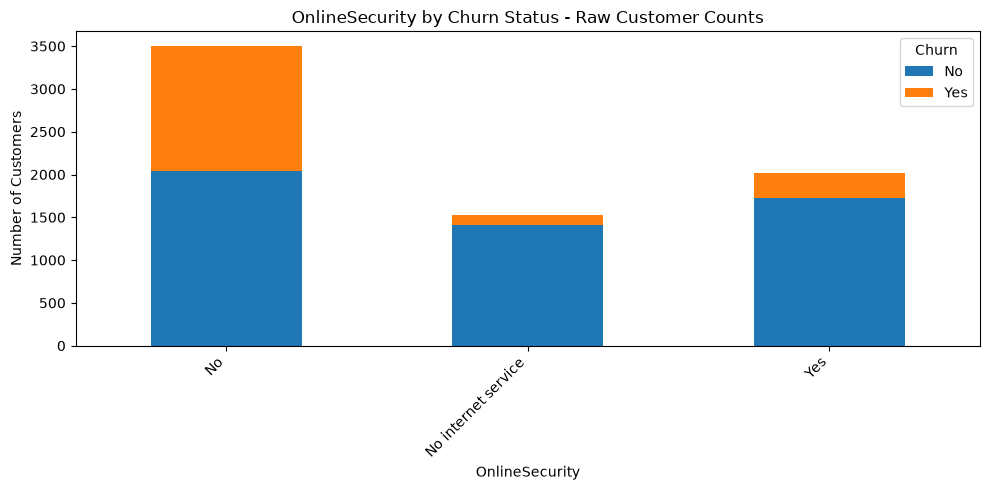

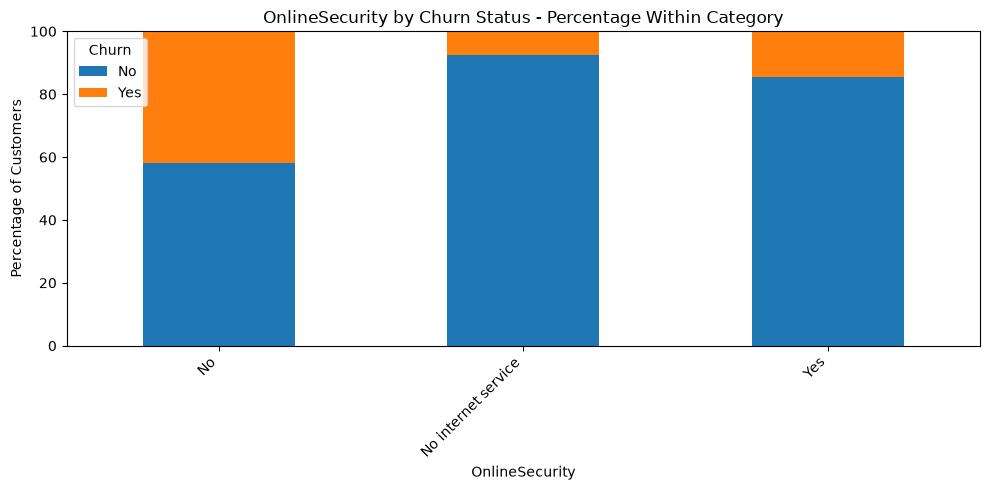


OnlineBackup vs. Churn
Raw counts:


Churn,No,Yes
OnlineBackup,,
No,1855,1233
No internet service,1413,113
Yes,1906,523


Percentage within each category:


Churn,No,Yes
OnlineBackup,,
No,60.07,39.93
No internet service,92.60,7.40
Yes,78.47,21.53


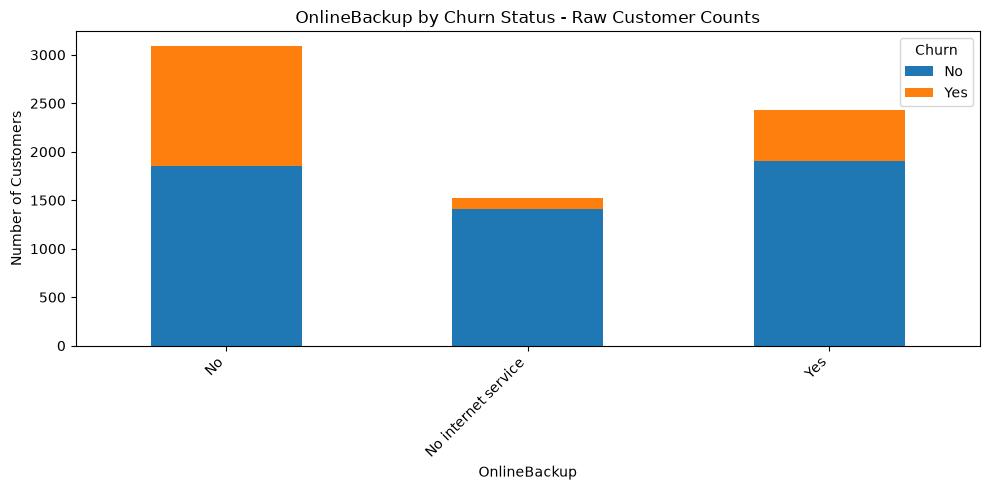

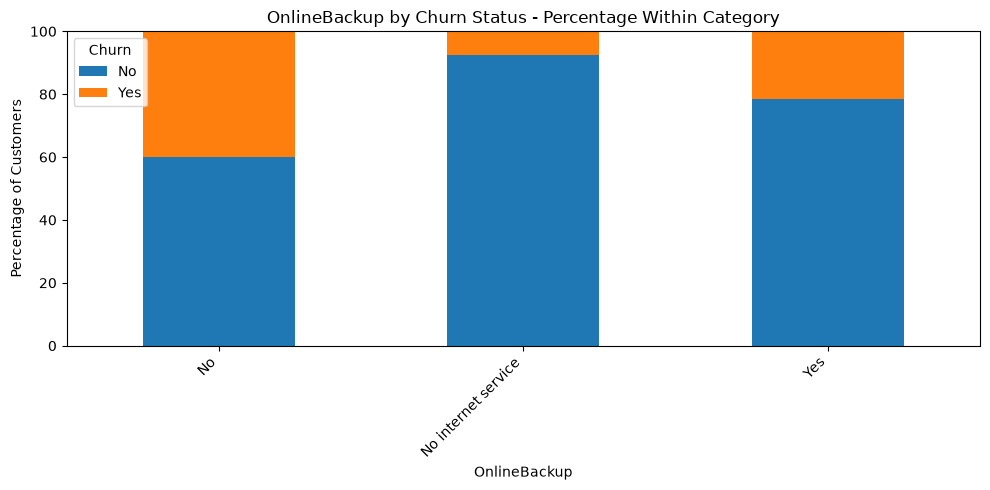


DeviceProtection vs. Churn
Raw counts:


Churn,No,Yes
DeviceProtection,,
No,1884,1211
No internet service,1413,113
Yes,1877,545


Percentage within each category:


Churn,No,Yes
DeviceProtection,,
No,60.87,39.13
No internet service,92.60,7.40
Yes,77.50,22.50


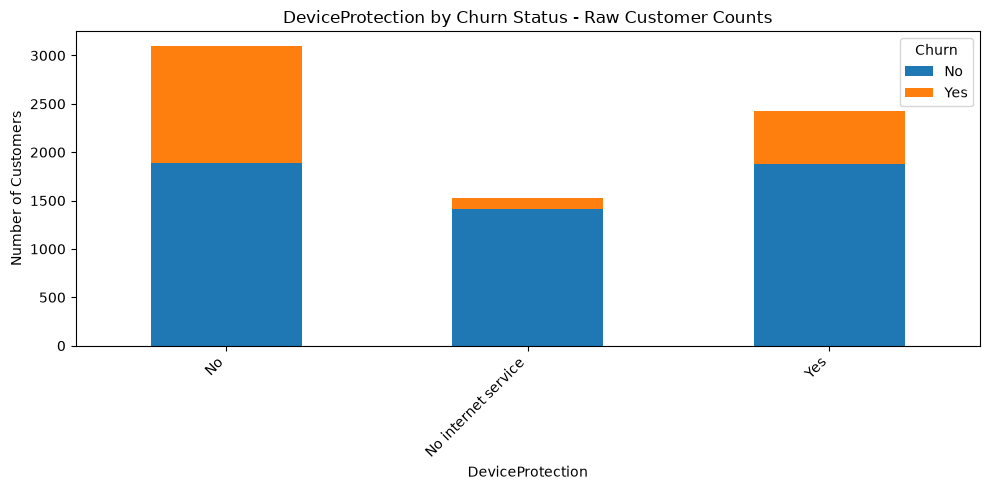

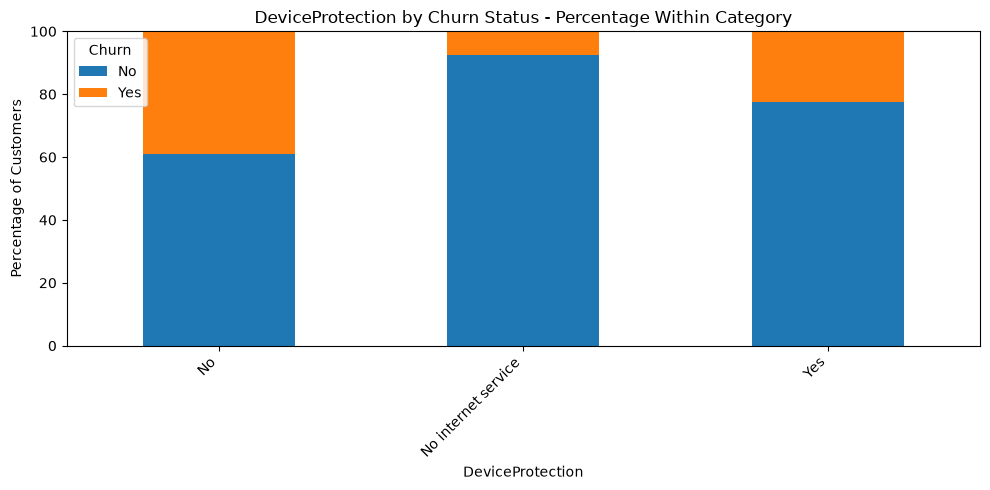


TechSupport vs. Churn
Raw counts:


Churn,No,Yes
TechSupport,,
No,2027,1446
No internet service,1413,113
Yes,1734,310


Percentage within each category:


Churn,No,Yes
TechSupport,,
No,58.36,41.64
No internet service,92.60,7.40
Yes,84.83,15.17


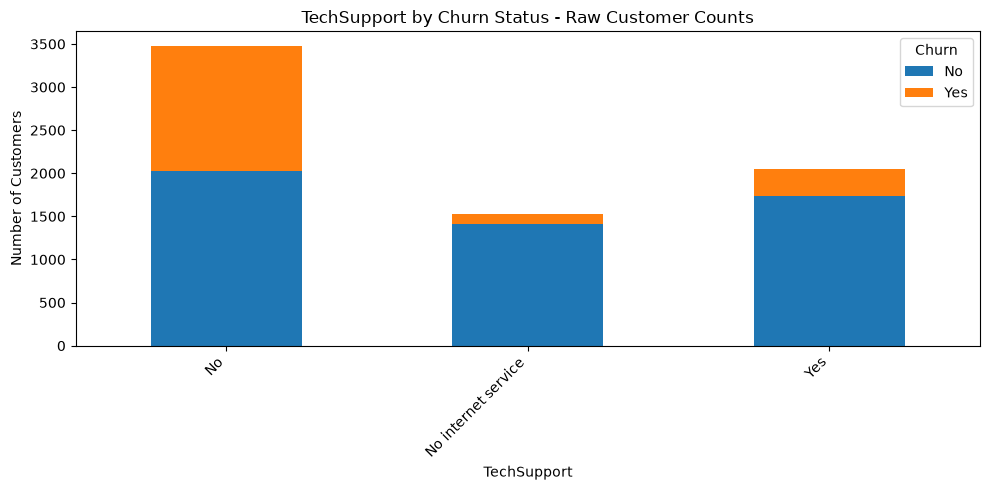

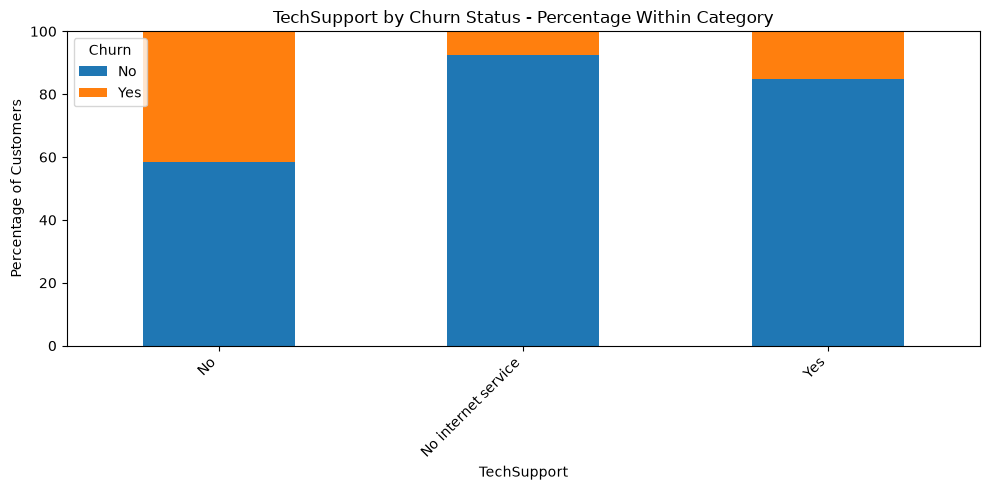


StreamingTV vs. Churn
Raw counts:


Churn,No,Yes
StreamingTV,,
No,1868,942
No internet service,1413,113
Yes,1893,814


Percentage within each category:


Churn,No,Yes
StreamingTV,,
No,66.48,33.52
No internet service,92.60,7.40
Yes,69.93,30.07


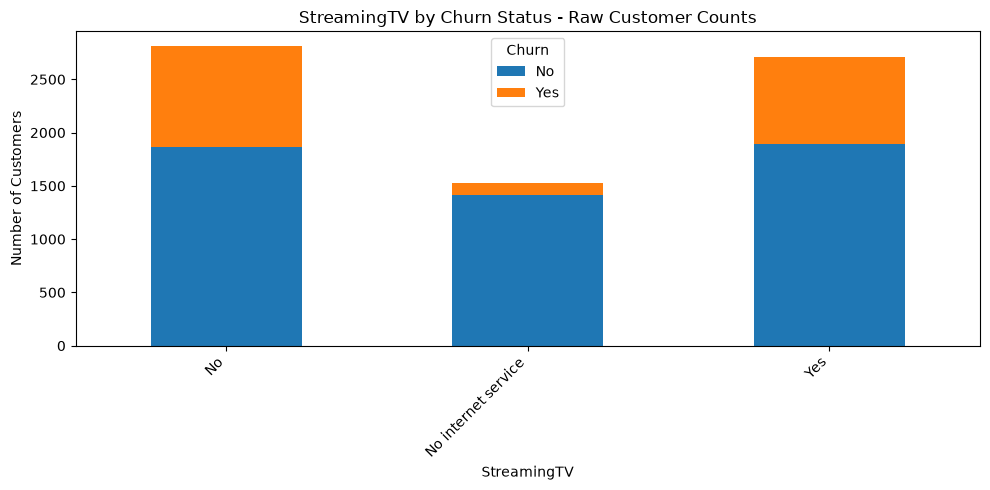

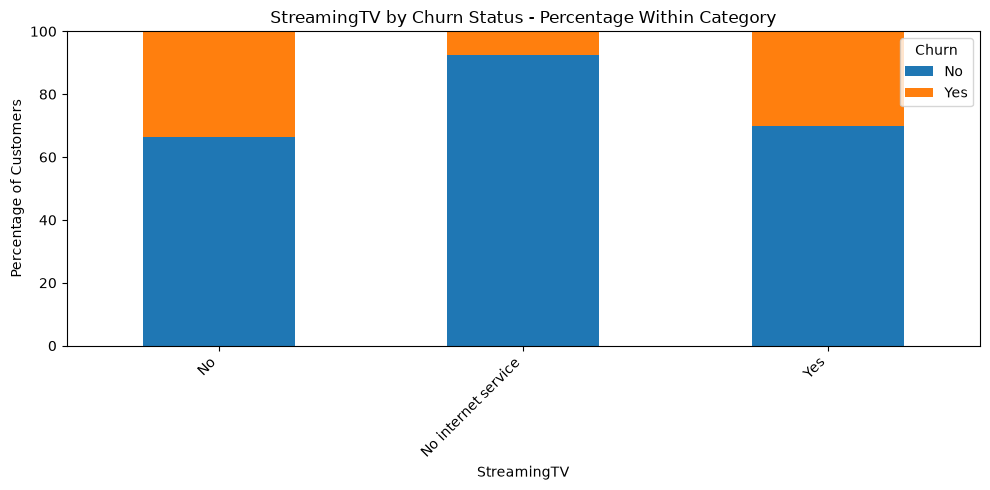


StreamingMovies vs. Churn
Raw counts:


Churn,No,Yes
StreamingMovies,,
No,1847,938
No internet service,1413,113
Yes,1914,818


Percentage within each category:


Churn,No,Yes
StreamingMovies,,
No,66.32,33.68
No internet service,92.60,7.40
Yes,70.06,29.94


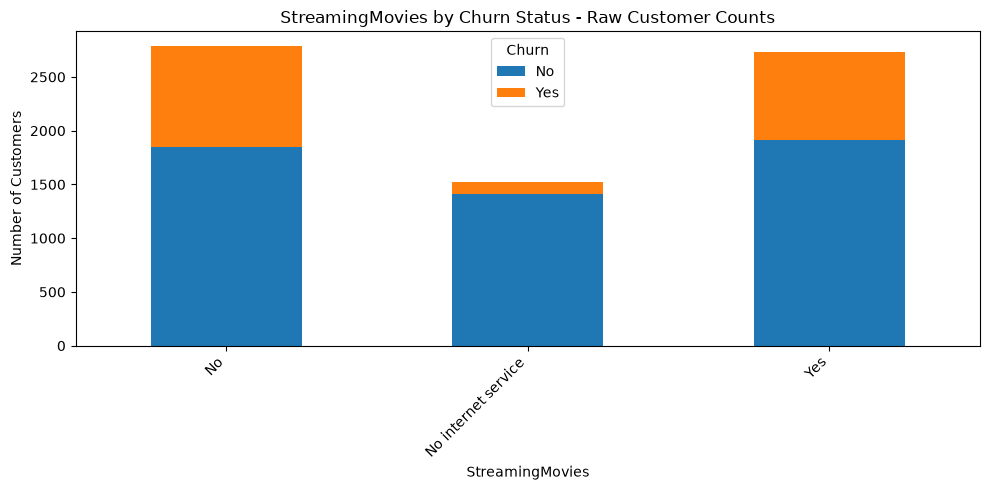

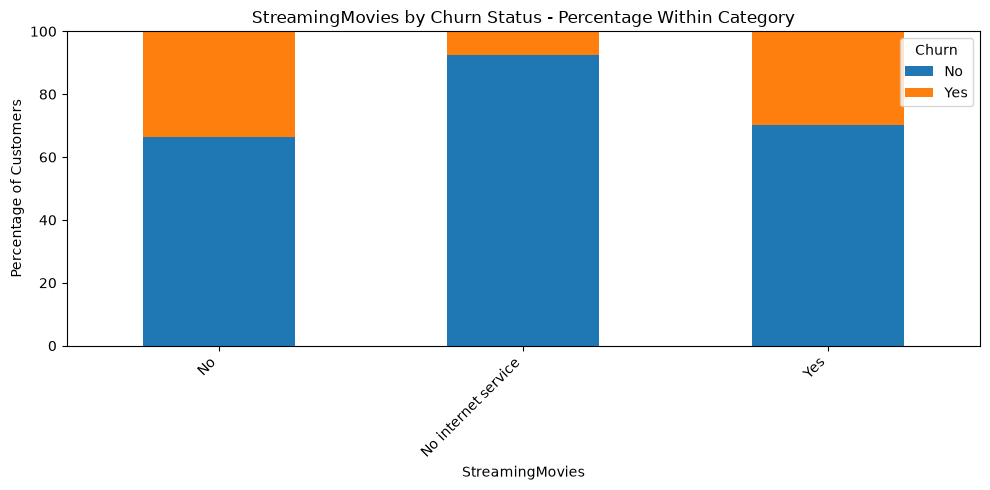


Contract vs. Churn
Raw counts:


Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


Percentage within each category:


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


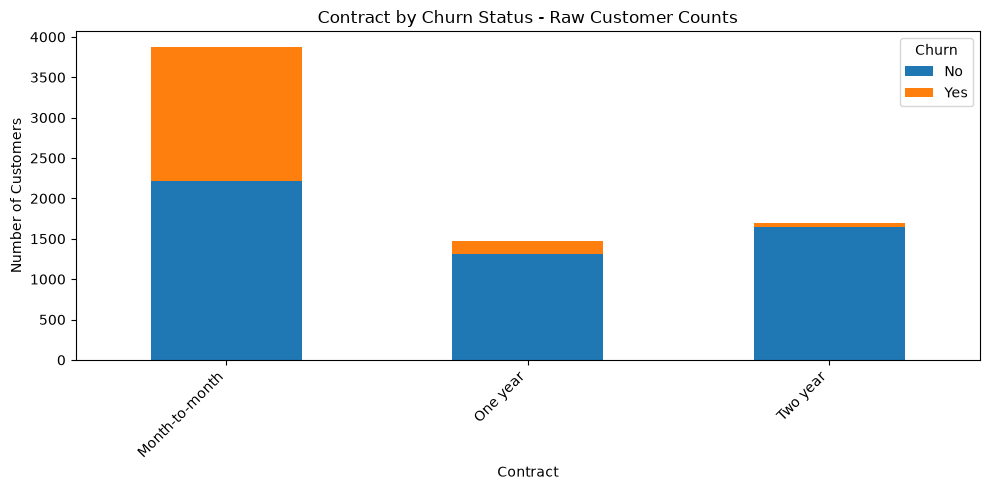

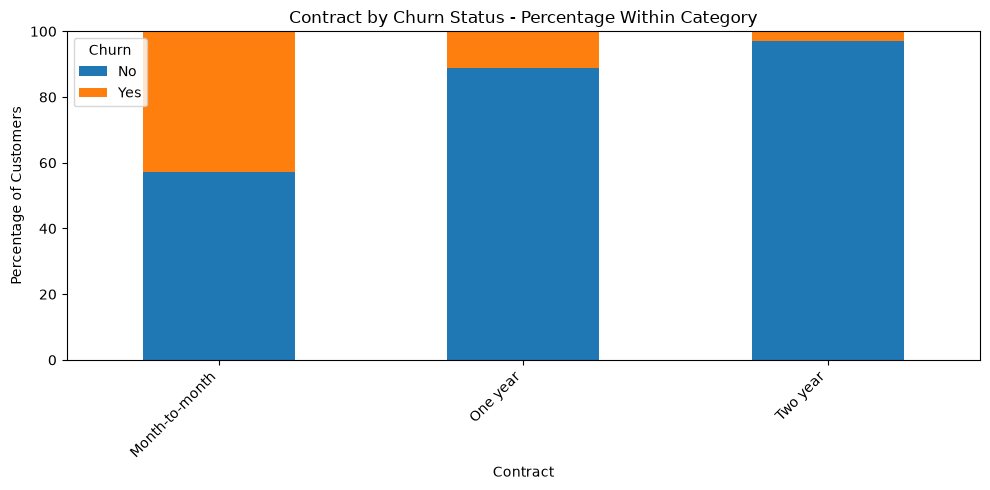


PaperlessBilling vs. Churn
Raw counts:


Churn,No,Yes
PaperlessBilling,,
No,2403,469
Yes,2771,1400


Percentage within each category:


Churn,No,Yes
PaperlessBilling,,
No,83.67,16.33
Yes,66.43,33.57


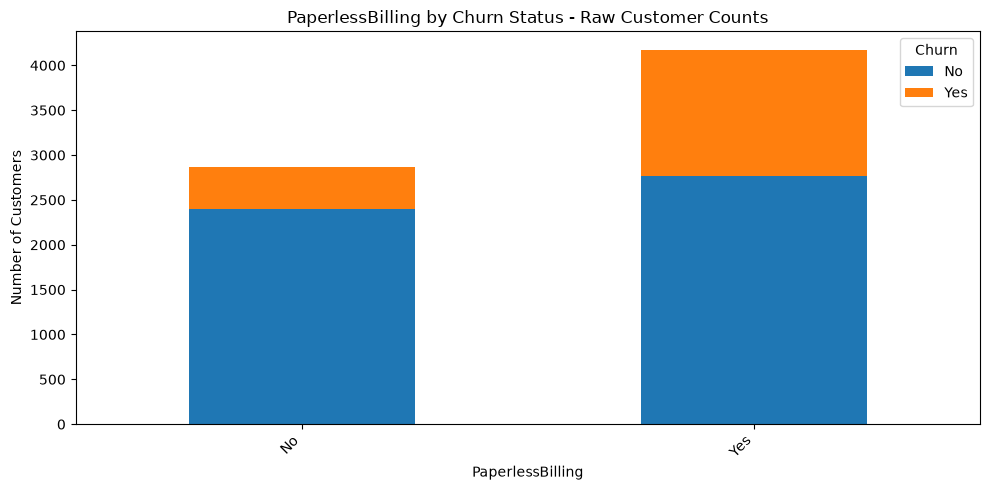

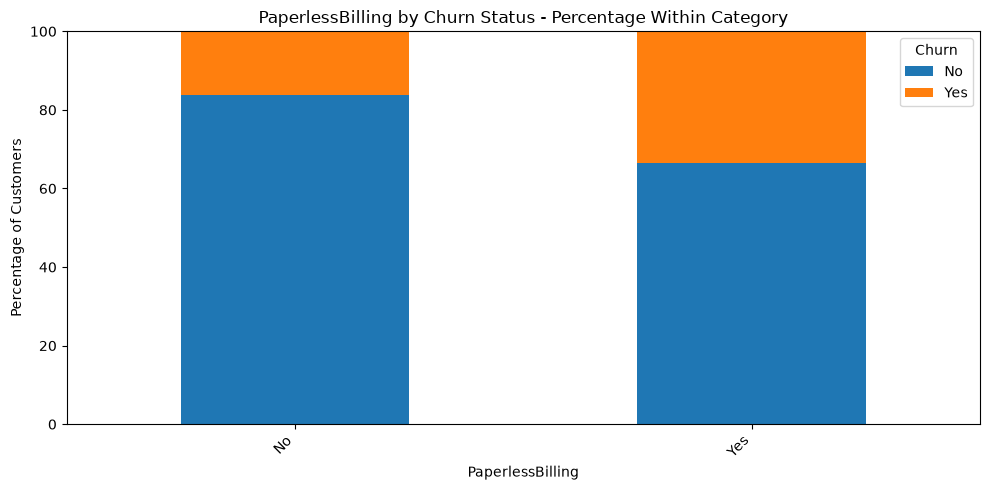


PaymentMethod vs. Churn
Raw counts:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308


Percentage within each category:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


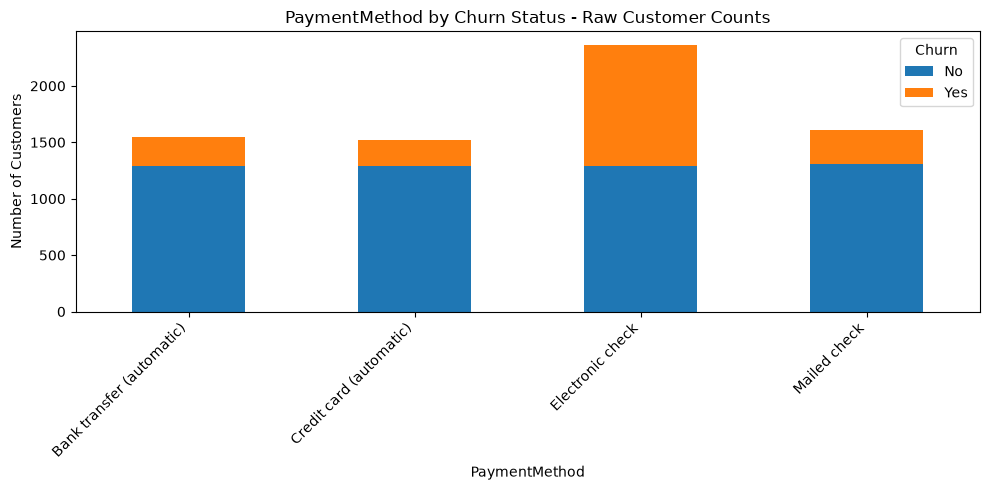

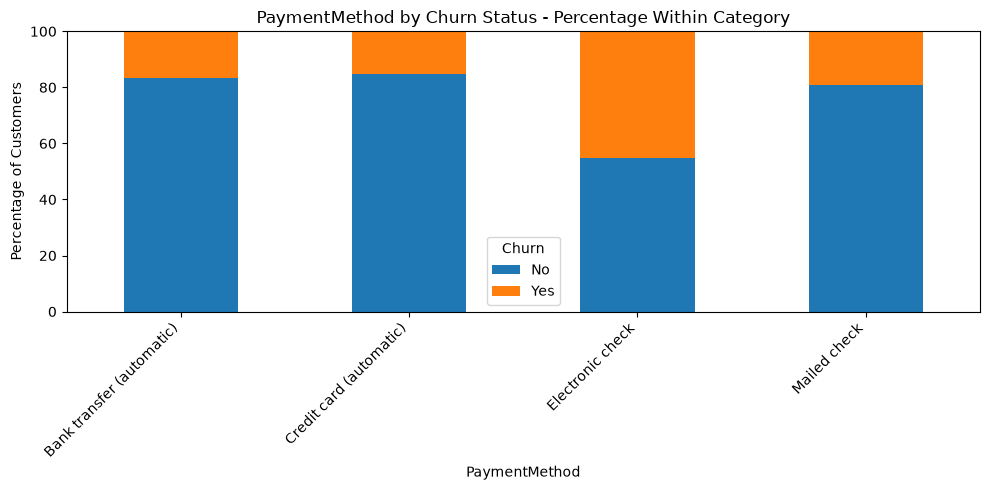

In [31]:
# Categorical features vs. Churn, with raw counts and percentages.


churn_col = "Churn"
binary_categorical_columns = ["SeniorCitizen"]

analysis_df = trans_df_1.copy()
if "SeniorCitizen" in analysis_df.columns:
    analysis_df["SeniorCitizen"] = analysis_df["SeniorCitizen"].map({0: "No", 1: "Yes"})

categorical_columns = analysis_df.select_dtypes(include=["object", "string", "category", "bool"]).columns.tolist()
categorical_columns = [column for column in categorical_columns if column != churn_col]

for column in categorical_columns:
    count_table = pd.crosstab(analysis_df[column], analysis_df[churn_col], dropna=False)
    percentage_table = pd.crosstab(
        analysis_df[column], analysis_df[churn_col], normalize="index", dropna=False
    ) * 100

    print(f"\n{column} vs. Churn")
    print("Raw counts:")
    display(count_table)
    print("Percentage within each category:")
    display(percentage_table.round(2))

    count_table.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )
    plt.title(f"{column} by Churn Status - Raw Customer Counts")
    plt.xlabel(column)
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    percentage_table.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )
    plt.title(f"{column} by Churn Status - Percentage Within Category")
    plt.xlabel(column)
    plt.ylabel("Percentage of Customers")
    plt.ylim(0, 100)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

Bivariate Analysis Output -

Retained customers generally have longer tenure, averaging 37.57 months versus 17.98 for churned customers, with a median of 38 versus 10 months.
Churned customers have higher monthly charges on average than retained customers: $74.44 versus $61.27, with medians of $79.65 versus $64.43; the churned group also appears more concentrated, despite retained customers having wider overall variability (STD 31.09 versus 24.67),  suggesting higher charges are associated with increased churn risk..

Retained customers have much higher lifetime total charges, averaging $2,549.91 versus $1,531.80, and a median of $1,679.53 versus $703.55.


Female customers have a slightly higher churn rate than male customers, 26.92% versus 26.16%.
Senior citizens have a substantially higher churn rate than non-senior citizens, 41.68% versus 23.61%
Customers without partners churn substantially more than customers with partners: 32.96% versus 19.66%.
Customers without dependents churn much more than those with dependents: 31.28% versus 15.45%.
Phone service customers have a slightly higher churn rate than customers without phone service: 26.71% versus 24.93%.
Customers with multiple lines churn more than those without, 28.61% versus 25.02%, although the difference is modest at 3.59 percentage points.
Customers with fiber optic internet have the highest churn rate at 41.89%, compared with 18.96% for DSL and 7.40% with no internet service.
Customers without online security churn more than customers with it, 41.77% versus 14.61%, while those without internet service have the lowest churn rate at 7.40%.
Customers without online backup churn much more than those with backup, 39.93% versus 21.53%, while customers without internet service have the lowest churn rate at 7.40%.
Customers without device protection churn more than those with protection, 39.13% versus 22.50%, while customers without internet service have the lowest churn rate at 7.40%.
Customers without tech support churn far more than those with support, 41.64% versus 15.17%, while customers without internet service have the lowest churn rate at 7.40%.
Streaming TV customers churn slightly less than non-subscribers, 30.07% versus 33.52%, while customers without internet service have the lowest churn rate at 7.40%.
Streaming Movies subscribers churn slightly less than non-subscribers, 29.94% versus 33.68%, while customers without internet service have the lowest churn rate at 7.40%.
Month-to-month customers have by far the highest churn rate at 42.71%, compared with 11.27% for one-year contracts and only 2.83% for two-year contracts.
Customers using paperless billing churn nearly twice as much as those using standard billing, 33.57% versus 16.33%.
Electronic-check customers have the highest churn rate at 45.29%, far above the other payment methods, which range from 15.24% to 19.11%.

In [32]:
# Comprehensive numerical EDA using Tukey's 1.5 x IQR outlier rule.

# Binary numeric fields should be interpreted as categorical variables.
binary_categorical_columns = ["SeniorCitizen"]
numeric_columns = trans_df_1.select_dtypes(include="number").columns.tolist()
numeric_columns = [column for column in numeric_columns if column not in binary_categorical_columns]

eda_rows = []
for column in numeric_columns:
    valid_values = trans_df_1[column].dropna()

    q1 = valid_values.quantile(0.25)
    median = valid_values.median()
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    lower_outliers = valid_values[valid_values < lower_bound]
    upper_outliers = valid_values[valid_values > upper_bound]
    total_outliers = lower_outliers.size + upper_outliers.size
    valid_count = valid_values.size

    eda_rows.append({
        "Column": column,
        "Mean": valid_values.mean(),
        "Median": median,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Lower Outlier Count": lower_outliers.size,
        "Upper Outlier Count": upper_outliers.size,
        "Total Outlier Count": total_outliers,
        "Lower Outlier %": lower_outliers.size / valid_count * 100 if valid_count else 0,
        "Upper Outlier %": upper_outliers.size / valid_count * 100 if valid_count else 0,
        "Total Outlier %": total_outliers / valid_count * 100 if valid_count else 0,
        "Skewness": valid_values.skew(),
        "Missing Count": trans_df_1[column].isna().sum(),
        "Missing %": trans_df_1[column].isna().mean() * 100
    })

numerical_eda = pd.DataFrame(eda_rows).set_index("Column")

percentage_columns = [
    "Lower Outlier %", "Upper Outlier %", "Total Outlier %", "Missing %"
]
numerical_eda_display = numerical_eda.copy()
for column_name in percentage_columns:
    numerical_eda_display[column_name] = numerical_eda_display[column_name].round(2).astype(str) + "%"

print("Numerical Column EDA Summary")
display(numerical_eda_display.round(4))

Numerical Column EDA Summary


,Mean,Median,Q1,Q3,IQR,Lower Bound,Upper Bound,Lower Outlier Count,Upper Outlier Count,Total Outlier Count,Lower Outlier %,Upper Outlier %,Total Outlier %,Skewness,Missing Count,Missing %
Column,,,,,,,,,,,,,,,,
tenure,32.3711,29.00,9.00,55.00,46.00,-60.000,124.000,0,0,0,0.0%,0.0%,0.0%,0.2395,0,0.0%
MonthlyCharges,64.7617,70.35,35.50,89.85,54.35,-46.025,171.375,0,0,0,0.0%,0.0%,0.0%,-0.2205,0,0.0%
TotalCharges,2279.7343,1394.55,398.55,3786.60,3388.05,-4683.525,8868.675,0,0,0,0.0%,0.0%,0.0%,0.9632,0,0.0%


Numerical EDA Metrics
Mean: Shows the average value, but is sensitive to extreme values.
Median: Shows the midpoint and is more robust than the mean for skewed data.
Q1 and Q3: Describe the central 50% of observations.
IQR: Measures the spread of the middle half of the data and helps identify unusual values.
Lower/upper bounds: Tukey boundaries calculated as 
Q1−1.5×IQR and 
Q3+1.5×IQR
Outlier counts and percentages: Identify how many and what proportion of observations fall outside the bounds.
Skewness: Measures distribution asymmetry:
Near 0: approximately symmetric
Positive: right-skewed, with a longer upper tail
Negative: left-skewed, with a longer lower tail
Missing count/percentage: Identify data quality problems that may require cleaning or imputation.
Together, these metrics provide evidence for transformations, outlier treatment, missing-value handling, and feature selection.



Tenure
Average tenure is 32.37 months, while the median is 29 months, indicating mild right skewness.
Values range from roughly 0 to 72 months, with 50% concentrated between 9 and 55 months.
The bounds are approximately -60 and 124 months, with no outliers.
No missing values are present.
Monthly Charges
The mean is $64.76 and the median is $70.35, so customers are slightly concentrated toward higher charges.
The middle 50% range from $35.50 to $89.85.
The bounds are approximately -46.03 and 171.38, with no outliers.
Skewness is -0.2205, indicating slight left skewness.
No missing values are present.
Total Charges
The mean is $2,279.73, considerably above the median of $1,394.55, indicating substantial right skewness.
The middle 50% range from $398.55 to $3,786.60.
Skewness of 0.9632 indicates a long upper tail.
The Tukey bounds contain all values, with no outliers.
No missing values are present.

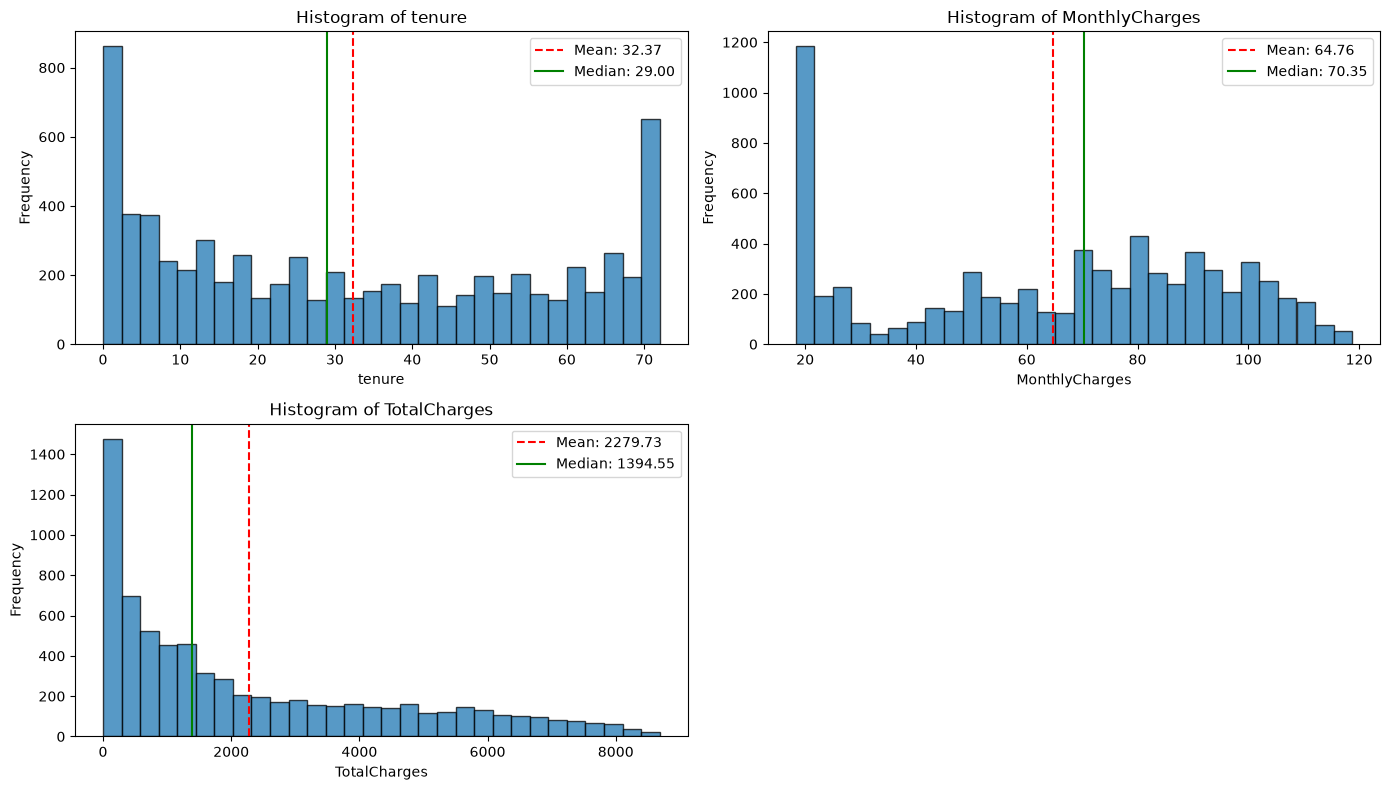

In [33]:
#Histograms for numeric features to visualize their distributions and identify potential outliers.

numeric_columns = trans_df_1.select_dtypes(include="number").columns
numeric_columns = numeric_columns.drop("SeniorCitizen", errors="ignore")

rows = (len(numeric_columns) + 1) // 2

fig, axes = plt.subplots(rows, 2, figsize=(14, 4 * rows))
axes = axes.flatten()

for ax, column in zip(axes, numeric_columns):
    values = trans_df_1[column].dropna()

    ax.hist(values, bins=30, edgecolor="black", alpha=0.75)
    ax.axvline(values.mean(), color="red", linestyle="--",
               label=f"Mean: {values.mean():.2f}")
    ax.axvline(values.median(), color="green",
               label=f"Median: {values.median():.2f}")

    ax.set_title(f"Histogram of {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    ax.legend()

for ax in axes[len(numeric_columns):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


tenure Quartile Bins - Raw Counts


Churn,No,Yes
tenure_Bin,,
"(-0.001, 9.0]",931,923
"(29.0, 55.0]",1395,324
"(55.0, 72.0]",1619,136
"(9.0, 29.0]",1229,486


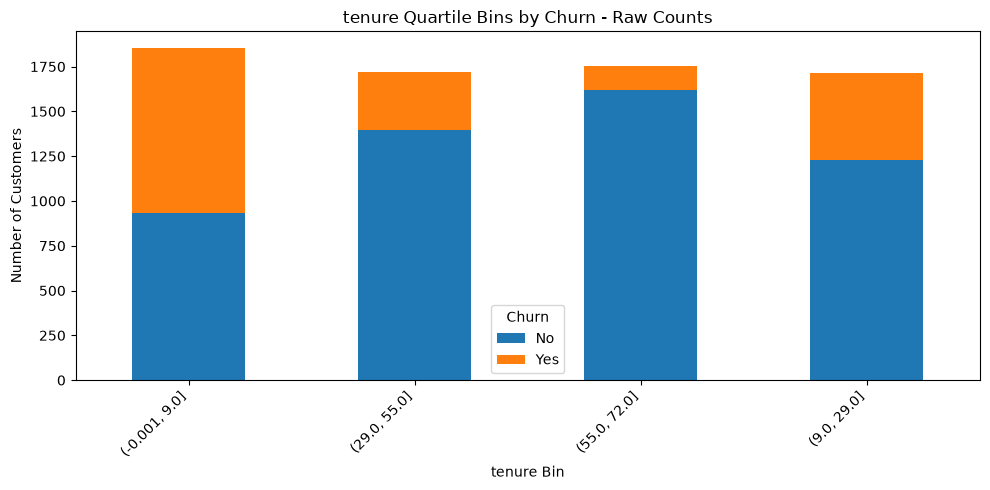


tenure Quartile Bins - Percentages


Churn,No,Yes
tenure_Bin,,
"(-0.001, 9.0]",50.22,49.78
"(29.0, 55.0]",81.15,18.85
"(55.0, 72.0]",92.25,7.75
"(9.0, 29.0]",71.66,28.34


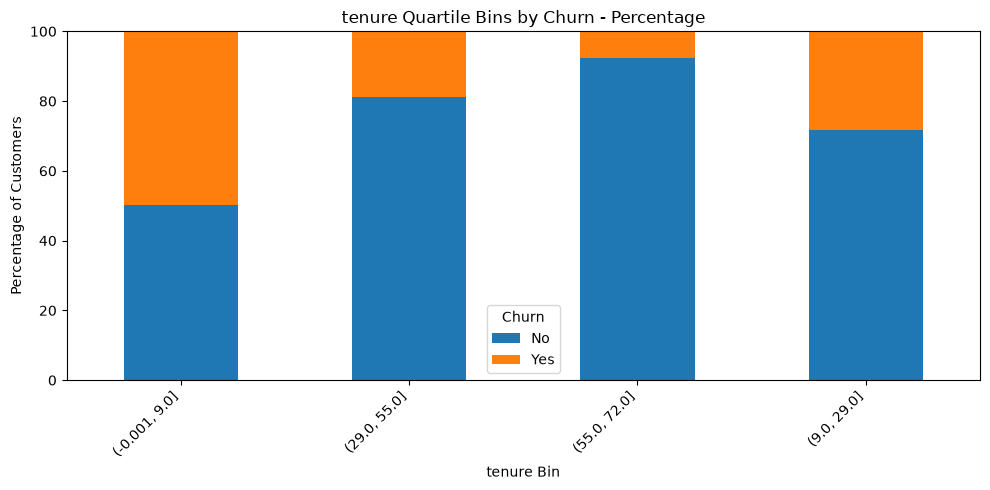


MonthlyCharges Quartile Bins - Raw Counts


Churn,No,Yes
MonthlyCharges_Bin,,
"(18.249, 35.5]",1564,198
"(35.5, 70.35]",1332,434
"(70.35, 89.85]",1098,659
"(89.85, 118.75]",1180,578


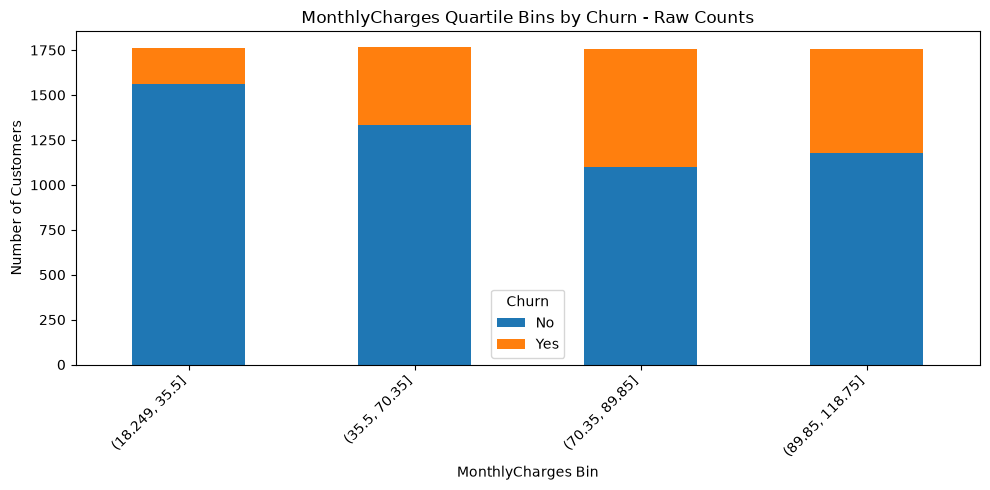


MonthlyCharges Quartile Bins - Percentages


Churn,No,Yes
MonthlyCharges_Bin,,
"(18.249, 35.5]",88.76,11.24
"(35.5, 70.35]",75.42,24.58
"(70.35, 89.85]",62.49,37.51
"(89.85, 118.75]",67.12,32.88


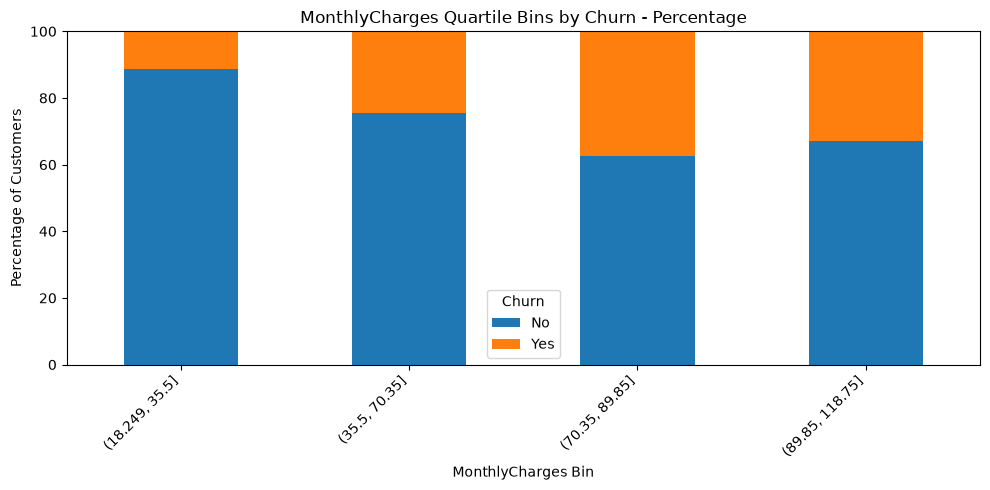


TotalCharges Quartile Bins - Raw Counts


Churn,No,Yes
TotalCharges_Bin,,
"(-0.001, 398.55]",1000,762
"(1394.55, 3786.6]",1355,405
"(3786.6, 8684.8]",1506,255
"(398.55, 1394.55]",1313,447


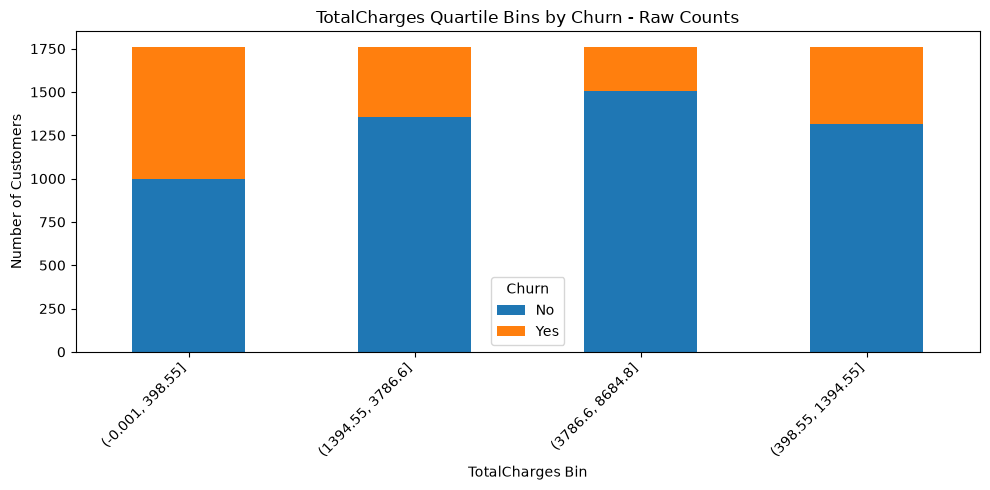


TotalCharges Quartile Bins - Percentages


Churn,No,Yes
TotalCharges_Bin,,
"(-0.001, 398.55]",56.75,43.25
"(1394.55, 3786.6]",76.99,23.01
"(3786.6, 8684.8]",85.52,14.48
"(398.55, 1394.55]",74.60,25.40


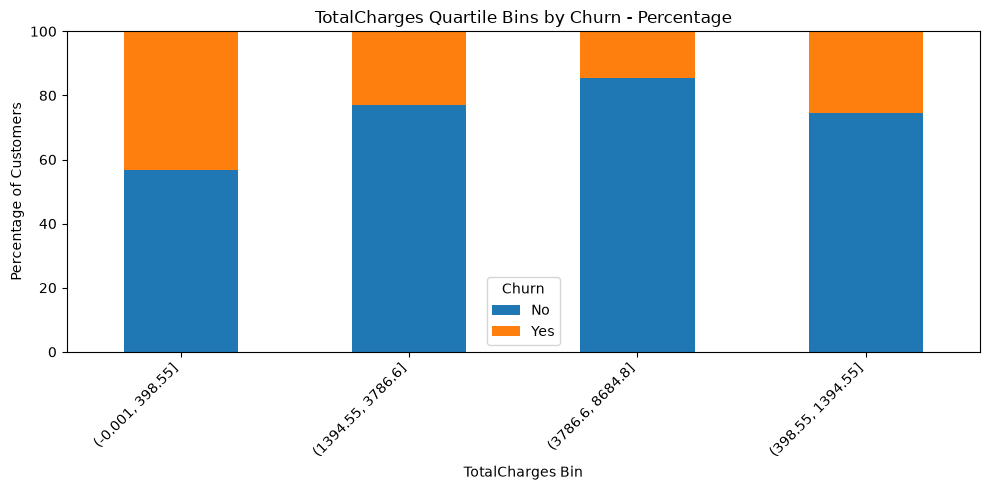

In [45]:
#bar graphs for numeric features vs. churn using quartile bins.

for column in numeric_columns:
    binned_column = f"{column}_Bin"

    trans_df_1[binned_column] = pd.qcut(
        trans_df_1[column],
        q=4,
        duplicates="drop"
    ).astype("string")

    count_table = pd.crosstab(
        trans_df_1[binned_column],
        trans_df_1["Churn"]
    )

    percentage_table = pd.crosstab(
        trans_df_1[binned_column],
        trans_df_1["Churn"],
        normalize="index"
    ) * 100

    print(f"\n{column} Quartile Bins - Raw Counts")
    display(count_table)

    count_table.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )
    plt.title(f"{column} Quartile Bins by Churn - Raw Counts")
    plt.xlabel(f"{column} Bin")
    plt.ylabel("Number of Customers")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print(f"\n{column} Quartile Bins - Percentages")
    display(percentage_table.round(2))

    percentage_table.plot(
        kind="bar",
        stacked=True,
        figsize=(10, 5)
    )
    plt.title(f"{column} Quartile Bins by Churn - Percentage")
    plt.xlabel(f"{column} Bin")
    plt.ylabel("Percentage of Customers")
    plt.ylim(0, 100)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

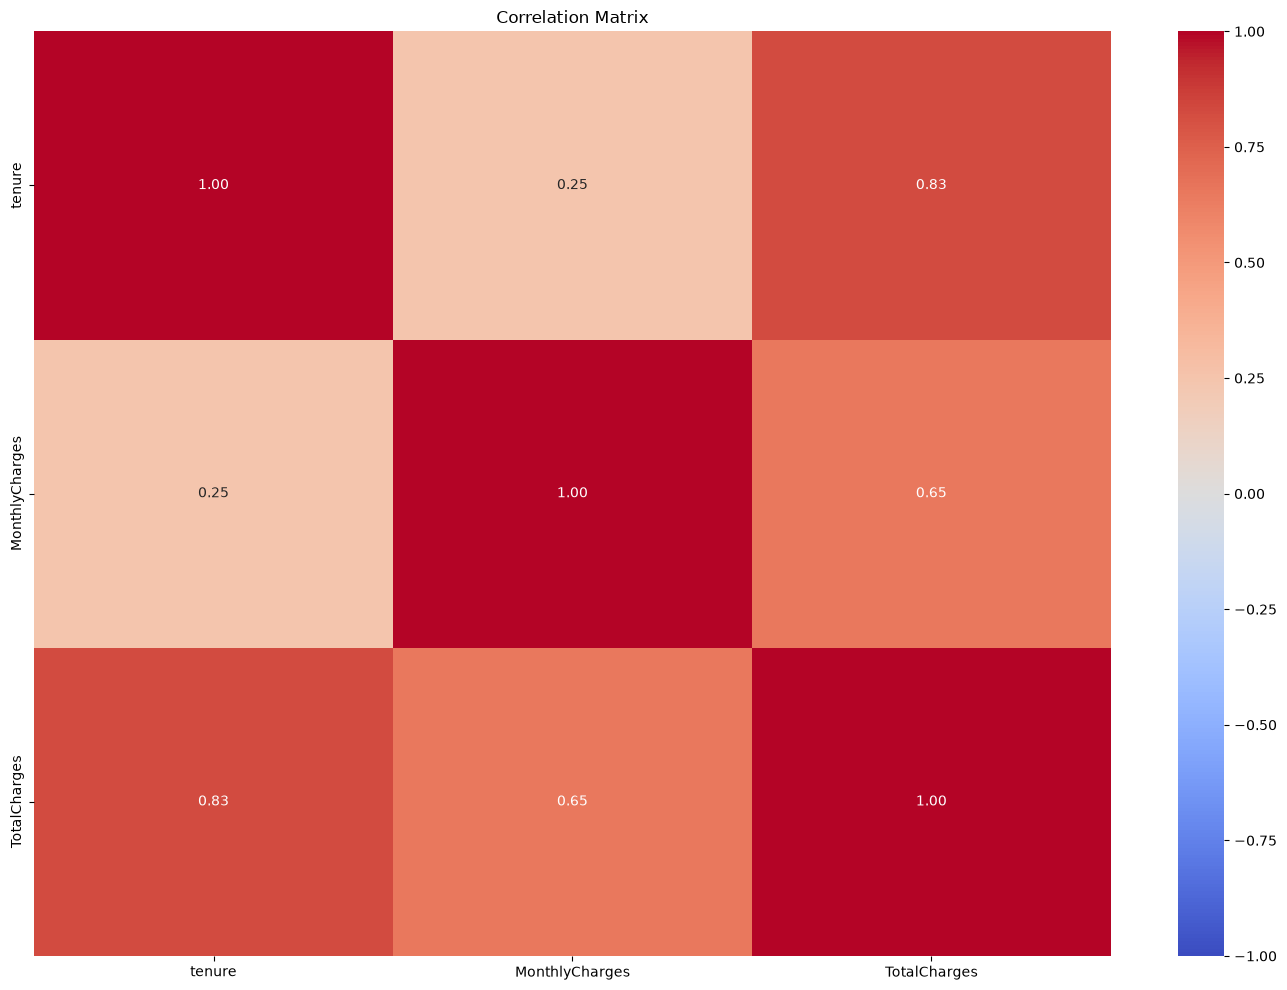

In [34]:
#Correaltion matrix heatmap useful when we have many numeric features and want to quickly identify which features are strongly correlated with each other. 
#This can help in feature selection, multicollinearity detection, and understanding the relationships between variables.

import matplotlib.pyplot as plt
import seaborn as sns

corr_matrix = analysis_df.select_dtypes(include="number").corr()

plt.figure(figsize=(14, 10))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()

In [35]:
corr_matrix = analysis_df.select_dtypes(include="number").corr()

display(corr_matrix)  # Full correlation-values table

# Then draw the heatmap

,tenure,MonthlyCharges,TotalCharges
tenure,1.000000,0.247900,0.826178
MonthlyCharges,0.247900,1.000000,0.651174
TotalCharges,0.826178,0.651174,1.000000


From correlation, it is evident that tenure and Total charges are correlated

In [ ]:
#H₀ (Null hypothesis): Online security status and customer churn are independent (no association).
#H₁ (Alternative hypothesis): Online security status and customer churn are associated.

#Test the association between the categorical variables "OnlineSecurity" and "Churn" using the Chi-Square test for independence.
chi2, p_value, dof, expected = stats.chi2_contingency(pd.crosstab(analysis_df['OnlineSecurity'], analysis_df['Churn']))
print(f"Chi-square statistic: {chi2:.2f}")
print(f"P-value: {p_value:.4f}")    
print(f"Degrees of freedom: {dof}")

Chi-Square Test of Independence — Conclusion

A Chi-square test of independence was performed to examine the association between online security status and customer churn. The test produced a Chi-square statistic of 850.00 with 2 degrees of freedom and a p-value below 0.001.

Since the p-value is below the 0.05 significance level, we reject the null hypothesis. There is statistically significant evidence of an association between online security status and customer churn.

In [67]:
#Hypothesis testing is a statistical method that allows us to make inferences or draw conclusions about a population based on sample data. In the context of customer churn analysis, hypothesis testing can help us determine whether certain factors (e.g., customer demographics, service usage patterns) have a statistically significant impact on the likelihood of a customer churning.

#Null Hypothesis (H0): Customers without online security are less likely to churn than those with online security.
#Alternative Hypothesis (H1): Customers without online security are more likely to churn than those with online security.

#conduct hypotheses testing to check whether given statements is statistically significant or not.
#  We will use the Chi-Square test for independence to test the relationship between the categorical variables "OnlineSecurity" and "Churn".

#set signficance level (alpha) to 0.05,willing to accept a 5% chance of making an error.
alpha = 0.05

#Keep only the rows where OnlineSecurity is either "Yes" or "No"
H_Data=analysis_df[analysis_df["OnlineSecurity"].isin(["Yes", "No"])]
print(H_Data.shape)

#get the churn values for customers with and without online security
without_security = H_Data[H_Data["OnlineSecurity"] == "No"]["Churn"]
with_security = H_Data[H_Data["OnlineSecurity"] == "Yes"]["Churn"]
print(without_security.value_counts())
    
#number of values in each category
#number of customers without online security and number of customers with online security

num_no_security = len(without_security)
num_with_security = len(with_security)

#raise an error if either group has zero customers, as this would make the hypothesis test invalid.
if num_no_security == 0 or num_with_security == 0:
    raise ValueError("Insufficient data for hypothesis testing.")

#get sum of churn from without security and with security groups
churn_no_security = (without_security == "Yes").sum()
churn_with_security = (with_security == "Yes").sum()

#calculate churn rates for both groups
churn_rate_no_security = churn_no_security / num_no_security
churn_rate_with_security = churn_with_security / num_with_security

print(f"Churn rate without online security: {churn_rate_no_security:.2f}")
print(f"Churn rate with online security: {churn_rate_with_security:.2f}")

#calculate overall churn rate
overall_churn_rate = (churn_no_security + churn_with_security) / (num_no_security + num_with_security)
print(f"Overall churn rate: {overall_churn_rate:.2f}")

#calculate standard error for the difference in proportions
standard_error = np.sqrt(
    overall_churn_rate * (1 - overall_churn_rate) * (1 / num_no_security + 1 / num_with_security)
)
print(f"Standard error: {standard_error:.2f}")

if standard_error == 0:
    raise ValueError("The standard error is zero; the z-test cannot be computed.")

#calculate z-score for the difference in proportions

z_score = (churn_rate_no_security - churn_rate_with_security) / standard_error
print(f"Z-score: {z_score:.2f}")

#A positive z-score means churn_rate_no_security is greater than churn_rate_with_security.
#A negative z-score means churn_rate_no_security is less than churn_rate_with_security.
#A larger positive score is stronger evidence for the claim that the no-security group churns more.

#confirm the direction of the z-score by checking the difference in churn rates USING one-sideed test
#calculate the p-value for the z-score using the complementary error function (erfc) from the math module. The p-value represents the probability of observing a test statistic as extreme as, or more extreme than, the observed value under the null hypothesis.

p_value=stats.norm.sf(abs(z_score))  # one-sided test

print(f"One-tailed P-value: {p_value:.4f}")

#The results provide strong statistical evidence that customers without online security have a higher churn rate than customers with online security, assuming your z-test and standard error are calculated correctly.


#two tailed test for the same hypothesis
#calculate the p-value for the two-tailed test by multiplying the one-sided p-value by
p_value_two_tailed = p_value * 2
print(f"Two-tailed P-value: {p_value_two_tailed:.4f}")

print(f"One-tailed p-value: {p_value:.3e}")
print(f"Two-tailed p-value: {p_value_two_tailed:.3e}")



(5517, 20)
Churn
No     2037
Yes    1461
Name: count, dtype: int64
Churn rate without online security: 0.42
Churn rate with online security: 0.15
Overall churn rate: 0.32
Standard error: 0.01
Z-score: 20.86
One-tailed P-value: 0.0000
Two-tailed P-value: 0.0000
One-tailed p-value: 6.439e-97
Two-tailed p-value: 1.288e-96


Types of Hypthesis testing & when to use -

1. One - Sample test - Test about single group, Ex - average score of student is 60 or not
2. Two - Sample test - compare means of two different groups. Ex - average score of RCB vs CSK matches
3. Paired Sample test - compare two sets of related data, same groups of things measured at two different time. Ex- data before diet and after diet
4. ANOVA - compare means of three or more groups. compare avg score from three different teaching methods.
5. Z Test and T - test 
    z - Test - SD is known and dataset count (Sample size) > 30
    T - Test - SD unknown and dataset (Sample size) <30

Direction way of testing -

One Tailed Test - to test in one direction, check the score > 50
Two tailed - to test either of the direction , check the score < 50 or >50

#Test the independence - 

Chi - Squared test - Dealing with categorical values (particularly - yes / No) - Test the independence of columns selected 
Fisher's exact test - 2*2 table, two categorical variables
G- Test - likelihood ratio test (categorical frequncy count data)
Permutation test - resampling based test (works with categorical or numerical dataset)

#Results from above example

Z score is more positive , churn rate without security is strong, then p value also less than 0.05 , then it is statistically Significant, Reject Null Hypothesis. Accept Alternative Hypothesis. 

"Finally it is evident that Customer without online security are more likely to churn"


